# Set Covering Problem — Constructive Heuristics, Local Search and Neighbourhood-Based Metaheuristics (SA and Tabu Search)

This notebook contains the full pipeline of the SCP assignment: constructive heuristics (CH1, CH2, CH3), redundancy elimination (RE), the two local-search neighbourhoods with first- and best-improvement (FI, BI), and the two neighbourhood-based metaheuristics **Simulated Annealing (SA)** and **Tabu Search (TS)**, together with the computational experiments, the statistical tests and the raw-data export required for the presentation.

### Contents
1. Imports, configuration and caching switches.
2. OR-Library instance reader.
3. Incremental solution state (`SCPInstance`).
4. Instance loading and best-known solutions (BKS, all 45 instances).
5. Constructive heuristics CH1 (random), CH2 (greedy cost/gain), CH3 (regret).
6. Redundancy elimination (RE).
7. Initial solutions, their validation, and the **common starting solution of the metaheuristics = the cheapest of CH1, CH2, CH3**.
8. Two neighbourhoods and iterative improvement (FI/BI): **N1** = 1-1 swap + RE, **N2** = remove one set + greedy repair + RE. These are the building blocks (and the BI baselines) of SA and TS.
9. **Simulated Annealing** with N1, N2 and MIX: calibrated cooling schedule, factorial tuning, final experiment.
10. Computational experiments on SA (parameters and building blocks) and figures.
11. **Tabu Search** with N1, N2 and MIX: design, implementation, factorial tuning, building-block ablation.
12. Final TS experiment and the **SA vs TS comparison under an identical evaluation budget**.
13. Statistical tests (Friedman, Wilcoxon + Holm), class breakdown, export of the raw data (spreadsheet + text file).
14. Persistence of the results.

### The three neighbourhood strategies (identical for SA and TS)
| Name | Move |
|---|---|
| **N1** | 1-1 swap (remove one selected set, add one unselected set that covers all its critical elements) followed by RE |
| **N2** | remove one selected set, repair greedily (min cost / newly covered elements), then RE |
| **MIX** | every proposed move is N1 with probability **0.9** and N2 with probability **0.1** (if no feasible swap exists for an N1 draw, the proposal falls back to N2) |

### What makes SA and TS comparable
| Aspect | SA | TS |
|---|---|---|
| Starting solution | cheapest of CH1, CH2, CH3 | same snapshot |
| Neighbourhoods | N1, N2, MIX (N1 90 % / N2 10 %) | same, **same neighbour sampler and exact evaluation** |
| Computing budget | fixed by the cooling schedule (`alpha`, `L_factor`, `p0`) | **exactly the same number of evaluated neighbours as the SA run with the same instance, variant and seed** (SA main loop + its 200 calibration evaluations) |
| Final step | best-improvement polish with the variant's own neighbourhood(s) | same polish |
| Parameter tuning | full factorial, 7 tuning instances (one per class), 3 seeds, no polish | full factorial, same 7 instances, 3 seeds, no polish, budget = that of the selected SA configuration |
| Final runs | all 45 instances, seeds 0-9 | same |
| Reported time | 3 CH constructions + search + polish | same |
| Statistics | per-instance mean % deviation over seeds, paired tests | same |

*Exercises 1.1/1.2 of the assignment (the 16-experiment table for CH + FI/BI) are not repeated here; this notebook only contains the code they share with the metaheuristics.*

### Summary of the fixes in this version

| # | Where | Problem found | Fix |
|---|---|---|---|
| 1 | Sec. 4 (BKS) | BKS table lacked 4.1, 4.10 and 5.10, so loading the real benchmark raised "Missing BKS values" | added the three values, `assert len(BKS) == 45` |
| 2 | Sec. 9, 10, 11 (text) | the text said SA-MIX uses N1 with probability 0.1, the code (and the assignment) use **0.9**; the TS note repeated the wrong statement; the E3 grid had no 0.9 level | text corrected everywhere (MIX = N1 90 % / N2 10 % for SA and TS); 0.9 added to the E3 grid |
| 3 | TS | not comparable to SA: 500 iterations x `abs(S)` samples = 4-10x more evaluations and time than SA, unrelated to SA's budget | TS now gets **exactly the number of evaluated neighbours of the matching SA run** (same instance, variant, seed); an assertion checks it |
| 4 | TS | no final polish although SA had one | same best-improvement polish for both |
| 5 | TS-MIX | N1/N2 drawn once per iteration, a failed N1 draw wasted the iteration (SA-MIX falls back to N2) | the draw is made per candidate, with the same N2 fallback |
| 6 | TS | long-term memory always active, counted additions only and ignored removed sets; text promised a residence memory with patience 20 | real residence frequencies, switched on after 20 non-improving iterations, penalise added and reward removed sets |
| 7 | TS | tenure and sample size hard-coded although the text said the tenure was tuned | factorial tuning of `tenure_factor` x `cand_factor` per variant; ablation uses the tuned values |
| 8 | TS (text) | claimed the whole neighbourhood is scanned, but a random sample was used; "BKS" used for the incumbent in the aspiration rule | documented as a candidate-list strategy; aspiration refers to the best cost of the run |
| 9 | SA | the 200 calibration evaluations were not counted in any budget | counted in the TS budget (`calib_evals` is also returned) |
| 10 | Sec. 13 | `export_raw_data(exclude=...)` ignored `exclude`; class plot ignored it; all 28 pairwise tests only | held-out matrix + all-instance matrix exported (xlsx + txt), matched SA-X vs TS-X tests with Holm correction added |
| 11 | Persistence | SA histories were only pickled in section 14, "recovery" cells overwrote variables and ran out of order | every experiment cell caches its CSV/pickle and checks that it matches the current settings (`RECOMPUTE` flags); recovery cells removed |
| 12 | Intro | described a 16-experiment table that is not in this notebook | introduction rewritten to describe what the notebook contains |
| 13 | Misc. | missing `display` import outside Jupyter, unused imports, figures never closed, deprecated seaborn call, no validation of the initial solutions | fixed / added (`validate_initial_solutions`) |

The neighbourhood evaluation (`_sim_swap`, greedy repair + RE) was checked against brute force: applying thousands of sampled N1/N2 moves and recomputing feasibility and cost never produced a mismatch, so the SA core itself was correct; the problems were in the experimental set-up, the TS implementation and the documentation.

## 1. Imports, configuration and caching switches

`DATA_DIR` is relative to the notebook's working directory; the OR-Library files must be in `SCP-Instances/` next to the notebook.

**Caching.** The experiments are expensive (SA and TS are run on all 45 instances with 10 seeds). Every experiment cell therefore writes its raw results to a CSV file and, when the cell is run again, **reuses the file if it exists and is consistent with the current settings** (same instances, seeds and parameter grid). Set the corresponding entry of `RECOMPUTE` to `True` to force a fresh run of that experiment. Delete the CSV files if you change the algorithms.

In [1]:
import heapq
import itertools
import math
import pickle
import random
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare, wilcoxon

try:                                    # inside Jupyter
    from IPython.display import display
except ImportError:                     # plain python fallback
    display = print


DATA_DIR = Path("SCP-Instances")
SEED = 42

# True  -> run the experiment again and overwrite its CSV file
# False -> reuse the CSV file if it exists and matches the current settings
RECOMPUTE = {
    "sa_tuning": False, "sa_final": False, "sa_extra": False,
    "ts_tuning": False, "ts_ablation": False, "ts_final": False,
}


def can_reuse(path, key):
    """True if the experiment `key` may be loaded from `path` instead of being recomputed."""
    return (not RECOMPUTE.get(key, False)) and Path(path).exists()

## 2. OR-Library SCP format

Each instance has the form

```text
m n
c_1 ... c_n
k_1 <k_1 column indices>
...
k_m <k_m column indices>
```

Here `m` is the number of elements (rows) and `n` is the number of available sets (columns). The file uses **1-based** column indices; the implementation converts them to **0-based** indices.

In [2]:
def read_scp_instance(filepath):
    """Read one SCP instance in OR-Library format.

    Format:
        m n
        c_1 ... c_n
        k_1 <k_1 column indices (1-based)>
        ...
        k_m <k_m column indices (1-based)>

    Returns dict containing m, n, costs array, rows list, and cols list.
    """
    filepath = Path(filepath)
    tokens = filepath.read_text().split()
    if len(tokens) < 2:
        raise ValueError(f"{filepath}: file is too short to contain m and n")

    values = [int(x) for x in tokens]
    idx = 0
    m, n = values[idx], values[idx + 1]
    idx += 2

    if m <= 0 or n <= 0:
        raise ValueError(f"{filepath}: invalid dimensions m={m}, n={n}")

    costs = np.asarray(values[idx : idx + n], dtype=float)
    idx += n

    rows = []
    for e in range(m):
        k = values[idx]
        idx += 1
        covering = [c - 1 for c in values[idx : idx + k]]  # Convert to 0-based
        idx += k
        rows.append(covering)

    cols = [[] for _ in range(n)]
    for e, covering in enumerate(rows):
        for j in covering:
            cols[j].append(e)

    return {"m": m, "n": n, "costs": costs, "rows": rows, "cols": cols}

## 3. Incremental solution state

The central idea is to avoid repeatedly recomputing coverage from scratch. For a partial solution we maintain:

| State | Meaning | Update/query | 
|---|---|---|
| `chosen[j]` | set `j` is selected | O(1) lookup | 
| `cover_count[e]` | number of selected sets covering element `e` | updated only when a set is added/removed | 
| `uncovered` + `_pos` | current uncovered elements | O(1) swap-remove/append | 
| `gain[j]` | number of currently uncovered elements that set `j` would cover | maintained incrementally | 
| `solution_cost` | total cost of selected sets | O(1) update | 

The key candidate condition is `gain[j] > 0`. Therefore a redundant set (`gain == 0`) is never selected during construction.

When an element changes from uncovered to covered, every set containing that element loses one unit of gain. During RE, the reverse update restores that gain if the element becomes uncovered again.

In [3]:
class SCPInstance:
    """Maintains incremental solution state for Set Covering Problem.

    State variables maintained in O(1) / O(k):
    - chosen: boolean mask of selected sets
    - cover_count: number of selected sets covering element e
    - gain: number of uncovered elements covered by set j
    - uncovered & _pos: O(1) list for fast sampling and state maintenance
    - solution_cost: total cost of currently chosen sets
    """

    def __init__(self, data, name=None):
        self.name = name
        self.m, self.n = data["m"], data["n"]
        self.costs = np.asarray(data["costs"], dtype=float)
        self.rows = data["rows"] # element -> covering sets (lists)
        self.cols = data["cols"]  # set -> covered elements (lists)
        self.rows_np = [np.asarray(r, dtype=np.int64) for r in self.rows]
        self.cols_np = [np.asarray(c, dtype=np.int64) for c in self.cols]
        self.col_size = np.asarray([len(c) for c in self.cols], dtype=np.int64)
        self.reset()

    # ---------------------------------------------------------------- state
    def reset(self):
        self.chosen = np.zeros(self.n, dtype=bool)
        self.cover_count = np.zeros(self.m, dtype=np.int64)
        self.gain = self.col_size.copy()    # nothing covered yet -> gain = column size
        self.uncovered = list(range(self.m))  # list of uncovered elements
        self._pos = np.arange(self.m, dtype=np.int64) # position of each element inside `uncovered`
        self.solution_cost = 0.0

    def snapshot(self):
        """Return a deep copy snapshot of current state."""
        return {
            "chosen": self.chosen.copy(),
            "cover_count": self.cover_count.copy(),
            "gain": self.gain.copy(),
            "uncovered": self.uncovered.copy(),
            "_pos": self._pos.copy(),
            "solution_cost": float(self.solution_cost),
        }

    def restore(self, state):
        """Restore instance state from a snapshot."""
        self.chosen = state["chosen"].copy()
        self.cover_count = state["cover_count"].copy()
        self.gain = state["gain"].copy()
        self.uncovered = state["uncovered"].copy()
        self._pos = state["_pos"].copy()
        self.solution_cost = float(state["solution_cost"])

    def is_complete_cover(self):
        return len(self.uncovered) == 0

    def solution_sets(self):
        return np.flatnonzero(self.chosen).tolist()
    
    # ------------------------------------------------ O(1) uncovered-list ops
    def _mark_covered(self, e):
        pos = int(self._pos[e])
        last = self.uncovered.pop()
        if last != e:
            self.uncovered[pos] = last
            self._pos[last] = pos
        self.gain[self.rows_np[e]] -= 1

    def _mark_uncovered(self, e):
        self._pos[e] = len(self.uncovered)
        self.uncovered.append(e)
        self.gain[self.rows_np[e]] += 1

    # ------------------------------------------------------------ mutations
    def add_set(self, j):
        j = int(j)
        if self.chosen[j]:
            return 0
        self.chosen[j] = True
        self.solution_cost += self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] += 1
        newly_covered = els[self.cover_count[els] == 1]
        for e in newly_covered:
            self._mark_covered(int(e))
        return len(newly_covered)

    def remove_set(self, j):
        j = int(j)
        if not self.chosen[j]:
            return 0
        self.chosen[j] = False
        self.solution_cost -= self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] -= 1
        newly_uncovered = els[self.cover_count[els] == 0]
        for e in newly_uncovered:
            self._mark_uncovered(int(e))
        return len(newly_uncovered)
    
    # -------------------------------------------------------------- queries
    def is_removable(self, j):
        """A set is removable if all its covered elements are covered by >= 2 sets."""
        return bool(np.all(self.cover_count[self.cols_np[int(j)]] > 1))
    
    # -------------------------------------------------------- verification
    def check_solution(self):
        """Verify feasibility and cost correctness."""
        covered = np.zeros(self.m, dtype=bool)
        for j in np.flatnonzero(self.chosen):
            covered[self.cols_np[j]] = True
        if not covered.all():
            raise AssertionError(f"{self.name}: incomplete set cover")
        if not np.isclose(self.solution_cost, self.costs[self.chosen].sum()):
            raise AssertionError(f"{self.name}: cost mismatch")

## 4. Instance loading and best-known solutions

The filename convention maps names such as `scp42.txt` to the label `4.2`, `scp410.txt` to `4.10` and `scpA3.txt` to `A.3`. Duplicate labels are rejected rather than silently overwritten.

The Best Known Solution (BKS) dictionary is kept separate from the heuristic code so that the percentage deviation is easy to audit. It contains the **45** benchmark instances (4.1-4.10, 5.1-5.10, 6.1-6.5, A.1-A.5, B.1-B.5, C.1-C.5, D.1-D.5). *Fix: the previous version lacked 4.1, 4.10 and 5.10, which made the loader raise "Missing BKS values" as soon as those files were present.* A check asserts that the table has 45 entries.

In [4]:
FNAME_RE = re.compile(r"scp([A-Za-z]|\d)(\d+)", re.IGNORECASE)

def label_from_filename(path):
    match = FNAME_RE.search(Path(path).name)
    if not match:
        return None
    group, num = match.groups()
    return f"{group.upper()}.{num}"

def sort_key(label):
    cls, num = label.split(".")
    return (cls, int(num))

def load_all_instances(data_dir):
    data_dir = Path(data_dir)
    if not data_dir.exists():
        return {}

    instances = {}
    for path in sorted(data_dir.iterdir()):
        if not path.is_file():
            continue
        label = label_from_filename(path)
        if label is None:
            continue
        if label in instances:
            raise ValueError(f"Duplicate instance label {label!r}: multiple files match it")
        instances[label] = SCPInstance(read_scp_instance(path), name=label)

    return dict(sorted(instances.items(), key=lambda kv: sort_key(kv[0])))

BKS = {
    "4.1": 429, "4.2": 512, "4.3": 516, "4.4": 494, "4.5": 512,
    "4.6": 560, "4.7": 430, "4.8": 492, "4.9": 641, "4.10": 514,
    "5.1": 253, "5.2": 302, "5.3": 226, "5.4": 242, "5.5": 211,
    "5.6": 213, "5.7": 293, "5.8": 288, "5.9": 279, "5.10": 265,
    "6.1": 138, "6.2": 146, "6.3": 145, "6.4": 131, "6.5": 161,
    "A.1": 253, "A.2": 252, "A.3": 232, "A.4": 234, "A.5": 236,
    "B.1": 69,  "B.2": 76,  "B.3": 80,  "B.4": 79,  "B.5": 72,
    "C.1": 227, "C.2": 219, "C.3": 243, "C.4": 219, "C.5": 215,
    "D.1": 60, "D.2": 66, "D.3": 72, "D.4": 62, "D.5": 61,
}

assert len(BKS) == 45, f"BKS table should have 45 entries, found {len(BKS)}"

instances = load_all_instances(DATA_DIR)
if not instances:
    print(f"No SCP instances found in {DATA_DIR.resolve()}. Add the Moodle files and rerun this section.")
else:
    missing_bks = sorted(set(instances) - set(BKS), key=sort_key)
    if missing_bks:
        raise ValueError(f"Missing BKS values for: {missing_bks}")
    print(f"Loaded {len(instances)} instance(s): {list(instances)}")
    not_found = sorted(set(BKS) - set(instances), key=sort_key)
    if not_found:
        print(f"WARNING: no file found for {len(not_found)} instance(s) listed in BKS: {not_found}. "
              "Check the data folder / file names (the standard benchmark has 45 instances).")

Loaded 42 instance(s): ['4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5.1', '5.2', '5.3', '5.4', '5.5', '5.6', '5.7', '5.8', '5.9', '6.1', '6.2', '6.3', '6.4', '6.5', 'A.1', 'A.2', 'A.3', 'A.4', 'A.5', 'B.1', 'B.2', 'B.3', 'B.4', 'B.5', 'C.1', 'C.2', 'C.3', 'C.4', 'C.5', 'D.1', 'D.2', 'D.3', 'D.4', 'D.5']


## 5. Constructive algorithms (CH1, CH2 and CH3)

* **CH1 (random):** repeatedly pick a random uncovered element and add a random set that covers it.
* **CH2 (greedy cost/gain):** repeatedly add the set with minimum `cost / gain`, where `gain` is the number of still-uncovered elements it covers (lazy heap, so stale entries are skipped).
* **CH3 (regret):** elements are processed by decreasing static regret (difference between the two cheapest sets covering the element); an uncovered element is covered by its set with minimum current `cost / gain`.

All three return a feasible cover but may contain redundant sets (RE is a separate step).

In [5]:
def ch1_random(inst, seed=SEED):
    """CH1: random uncovered element + random set covering it."""
    rnd = random.Random(seed)
    inst.reset()
    while not inst.is_complete_cover():
        e = rnd.choice(inst.uncovered)
        j = rnd.choice(inst.rows[e])
        inst.add_set(j)
    return inst.solution_cost


def ch2_greedy(inst):
    """CH2: dynamic minimum cost/gain, implemented with a lazy heap."""
    inst.reset()
    costs = inst.costs

    heap = [
        (float(costs[j] / inst.gain[j]), j)
        for j in range(inst.n)
        if inst.gain[j] > 0
    ]
    heapq.heapify(heap)

    while not inst.is_complete_cover():
        # Lazy deletion: heap entries become stale when a set's gain changes.
        while heap:
            ratio, j = heapq.heappop(heap)
            if inst.chosen[j] or inst.gain[j] <= 0:
                continue
            current_ratio = float(costs[j] / inst.gain[j])
            if ratio == current_ratio:
                break
        else:
            raise RuntimeError(f"{inst.name}: no positive-gain candidate remains")

        # These elements are the only ones whose coverage/gain will change.
        els = inst.cols_np[j]
        newly_covered = els[inst.cover_count[els] == 0]
        inst.add_set(j)

        # Every set containing a newly covered element has had its gain reduced.
        touched = set()
        for e in newly_covered:
            touched.update(int(s) for s in inst.rows_np[int(e)])

        for s in touched:
            if not inst.chosen[s] and inst.gain[s] > 0:
                heapq.heappush(heap, (float(costs[s] / inst.gain[s]), s))

    return inst.solution_cost


def compute_regret(inst):
    """Return one static regret value per element."""
    regret = np.empty(inst.m, dtype=float)
    for e, covering_sets in enumerate(inst.rows_np):
        costs = inst.costs[covering_sets]
        if len(costs) < 2:
            regret[e] = np.inf
        else:
            two_smallest = np.partition(costs, 1)[:2]
            regret[e] = float(two_smallest[1] - two_smallest[0])
    return regret


def ch3_regret(inst, regret=None):
    """CH3: process elements by decreasing regret; choose best current cost/gain set."""
    if regret is None:
        regret = compute_regret(inst)

    inst.reset()
    order = np.argsort(-regret, kind="stable")
    for e in order:
        if inst.cover_count[e] > 0:
            continue
        cand = inst.rows_np[e]
        scores = inst.costs[cand] / inst.gain[cand]
        j = cand[int(np.argmin(scores))]
        inst.add_set(j)

    return inst.solution_cost


HEURISTICS = {
    "CH1 (random)": ch1_random,
    "CH2 (cost/gain)": ch2_greedy,
    "CH3 (regret)": ch3_regret,
}

## 6. Redundancy elimination (RE)

RE removes, once and in a given order, every selected set whose elements are all covered by at least two selected sets (checked at removal time, so removing one set can make another one non-removable). Default order: decreasing cost. Inside the neighbourhoods an equivalent simulated version (`_re_simulate`) is used.

In [6]:
RE_ORDERS = ["cost_desc", "random", "cost_per_element"]

def redundancy_elimination(inst, order="cost_desc", seed=SEED):
    """Remove redundant selected sets once, in the requested order."""
    if not inst.is_complete_cover():
        raise ValueError("RE must start from a complete cover")

    sets = inst.solution_sets()
    if order == "cost_desc":
        sets.sort(key=lambda j: (-inst.costs[j], j))
    elif order == "random":
        random.Random(seed).shuffle(sets)
    elif order == "cost_per_element":
        sets.sort(
            key=lambda j: (
                -(inst.costs[j] / len(inst.cols_np[j]) if len(inst.cols_np[j]) else np.inf),
                j,
            )
        )
    else:
        raise ValueError(f"Unknown RE order: {order}")

    for j in sets:
        if inst.is_removable(j):
            inst.remove_set(j)

    return inst.solution_cost

## 7. Construction of initial solutions

One initial solution is built per instance for CH1, CH2, CH3 and CH1+RE (RE applied to the same CH1 solution). For each of them the cost, a state snapshot and the construction time are stored, so that total computing time (construction + search) can be reported later.

In [7]:
def generate_initial_solutions(instances, bks_dict):
    """Generate the 4 required initial solutions (CH1, CH2, CH3, CH1+RE) for each
    instance. Each entry is (cost, snapshot, construction_time_s).

    CH1+RE is obtained by applying RE to the *same* CH1 solution, so CH1 and
    CH1+RE differ only by the RE step. Construction times are recorded so that
    total computation time (construction + local search) can be reported.
    """
    prepared_instances = {}

    for label, inst in instances.items():
        if label not in bks_dict:
            print(f"Skipping {label}: No BKS found.")
            continue

        instance_states = {}

        t0 = time.perf_counter()
        precomputed_regret = compute_regret(inst)
        regret_time = time.perf_counter() - t0

        for method, construct in HEURISTICS.items():
            if "CH1" in method:
                t0 = time.perf_counter()
                cost_ch1 = construct(inst, seed=SEED)
                t_ch1 = time.perf_counter() - t0
                instance_states["CH1"] = (cost_ch1, inst.snapshot(), t_ch1)

                # RE applied to that very same CH1 solution
                t0 = time.perf_counter()
                cost_ch1_re = redundancy_elimination(inst, order="cost_desc", seed=SEED)
                t_re = time.perf_counter() - t0
                instance_states["CH1+RE"] = (cost_ch1_re, inst.snapshot(), t_ch1 + t_re)

            elif "CH3" in method:
                t0 = time.perf_counter()
                cost_ch3 = construct(inst, regret=precomputed_regret)
                t_ch3 = time.perf_counter() - t0 + regret_time
                instance_states["CH3"] = (cost_ch3, inst.snapshot(), t_ch3)

            else:  # CH2
                t0 = time.perf_counter()
                cost_ch2 = construct(inst)
                t_ch2 = time.perf_counter() - t0
                instance_states["CH2"] = (cost_ch2, inst.snapshot(), t_ch2)

        prepared_instances[label] = instance_states

    return prepared_instances


if instances:
    initial_solutions_data = generate_initial_solutions(instances, BKS)
    print(f"Successfully generated 4 initial solutions for {len(initial_solutions_data)} instances.")
else:
    print("Real experiment skipped: no SCP instance files were found.")

Successfully generated 4 initial solutions for 42 instances.


### Validation of the initial solutions

Every stored snapshot is restored and checked: complete cover, and the incrementally maintained cost equals the recomputed cost. This catches state-maintenance bugs before any search is run.

In [8]:
def validate_initial_solutions(instances, initial_solutions_data):
    """Every snapshot must be a complete cover whose stored cost matches the recomputed cost."""
    n = 0
    for label, states in initial_solutions_data.items():
        inst = instances[label]
        for name, (cost, snap, _) in states.items():
            inst.restore(snap)
            inst.check_solution()                       # raises if infeasible or cost mismatch
            assert abs(inst.solution_cost - cost) < 1e-6, f"{label}/{name}: stored cost differs"
            n += 1
    print(f"OK: {n} initial solutions are feasible and consistent.")


if instances and initial_solutions_data:
    validate_initial_solutions(instances, initial_solutions_data)

OK: 168 initial solutions are feasible and consistent.


### Common starting solution for the metaheuristics

SA and Tabu Search both start from the **cheapest of CH1, CH2 and CH3** (`START_RULE = "BEST3"`), so that any difference between them comes from the algorithms and not from the starting point. CH1+RE is *not* a candidate (it is only used as an additional starting point of the local-search experiments). All three constructions are run, so their construction times are added to the reported computing time. Set `START_RULE` to `"CH2"` (or another heuristic) to use a single constructive heuristic.

In [9]:
# ----------------------------------------------------------------------------
# Common starting solution for ALL metaheuristics (SA and Tabu Search)
# ----------------------------------------------------------------------------
START_CANDIDATES = ("CH1", "CH2", "CH3")
START_RULE = "BEST3"        # "BEST3" = cheapest of CH1, CH2, CH3; or one of "CH1", "CH2", "CH3", "CH1+RE"


def best_constructive_start(initial_solutions_data_for_label, candidates=START_CANDIDATES):
    """Return (name, cost, snapshot, construction_time) of the cheapest CH solution.
    Construction time is the sum of the three CH times (all three are run)."""
    data = initial_solutions_data_for_label
    name = min(candidates, key=lambda h: data[h][0])
    cost, snap, _ = data[name]
    total_time = sum(data[h][2] for h in candidates)
    return name, cost, snap, total_time


def get_start(initial_solutions_data_for_label, rule=START_RULE):
    """Starting solution according to `rule`: (name, cost, snapshot, construction_time)."""
    if rule == "BEST3":
        return best_constructive_start(initial_solutions_data_for_label)
    cost, snap, t = initial_solutions_data_for_label[rule]
    return rule, cost, snap, t

## 8. Iterative improvement: two neighborhoods, FI and BI

We compare two local-search neighborhoods. **RE is applied after every accepted move** (it is part of the move). The starting solution is used as it is: there is no RE before the first move, so CH1 and CH1+RE remain genuinely different starting points.

### Neighborhood N1: 1–1 swap + RE
Choose a selected set `i` and an unselected set `k`. The swap is feasible when `k` covers every **critical element** of `i` (an element covered only by `i`). After the swap, RE removes any selected set that has become redundant (one entering set can make several sets redundant).

### Neighborhood N2: remove one set + greedy repair + RE
Choose a selected set `i` and remove it. The elements it alone covered become uncovered; they are re-covered greedily by repeatedly adding the set with minimum `cost / (newly covered elements)` (set `i` may not re-enter). The repair can add **several** sets, so this is a different kind of move from a swap. RE is then applied. N2 has only |S| neighbors, so scanning it is cheap.

### Exact evaluation
Both neighborhoods are evaluated exactly, including RE, **before** a move is accepted: a move is accepted only if the final cost after RE is strictly lower than the current cost. (Predicting the effect of RE analytically can be wrong when two sets are individually redundant but not jointly removable; here the swap neighborhood uses the analytical prediction only as a lower bound to skip hopeless candidates and then re-evaluates exactly.) The search therefore always terminates in a local optimum.

### Speed
Swap moves are evaluated for all candidate sets at once with one matrix product, and FI is a *true* first improvement: it scans a random permutation lazily in chunks and stops at the first improving move, instead of building the whole neighborhood.

FI and BI receive exactly the same saved starting snapshot per instance/heuristic. A fixed seed randomizes FI's scan order reproducibly. No time limit is used, so both algorithms end in a local optimum.

In [10]:
EPS = 1e-9

# ----------------------------------------------------------------------------
# Matrices used to evaluate a whole neighborhood at once 
# ----------------------------------------------------------------------------
def build_matrices(inst):
    """A[k, e] = 1 if set k covers element e."""
    A = np.zeros((inst.n, inst.m), dtype=np.float32)
    for j in range(inst.n):
        A[j, inst.cols_np[j]] = 1.0
    return A, np.ascontiguousarray(A.T)


def _critical_matrix(inst):
    """Selected sets, their critical-element matrix C (|S| x m) and |crit| per set."""
    sel = np.flatnonzero(inst.chosen)
    C = np.zeros((len(sel), inst.m), dtype=np.float32)
    for r, s in enumerate(sel):
        els = inst.cols_np[s]
        C[r, els[inst.cover_count[els] == 1]] = 1.0
    return sel, C, C.sum(axis=1)


def _re_simulate(inst, cc, candidates):
    """Redundancy elimination on a copy of the cover counts `cc` (modified in place)"""

    removed = []
    for s in sorted(candidates, key=lambda s: (-inst.costs[s], s)):
        els = inst.cols_np[s]
        if np.all(cc[els] > 1):
            cc[els] -= 1
            removed.append(int(s))
    return removed


def _move(cost, add, remove):
    return {"cost": float(cost), "add": add, "remove": remove}


# ----------------------------------------------------------------------------
# Neighborhood N1: 1-1 swap + RE
# ----------------------------------------------------------------------------
def _sim_swap(inst, i, k, removable_k):
    """Exact result of: remove i, add k, then RE. """
    cc = inst.cover_count.copy()
    cc[inst.cols_np[i]] -= 1
    cc[inst.cols_np[k]] += 1
    candidates = [int(s) for s in removable_k if s != i] + [k]
    removed = _re_simulate(inst, cc, candidates)
    cost = (inst.solution_cost - inst.costs[i] + inst.costs[k]
            - sum(inst.costs[s] for s in removed))
    return _move(cost, [k], [i] + removed)


def _swap_scan(inst, mats, mode, rng, chunk=256):
    """Return an improving 1-1 swap+RE move (FI: first found in a random scan,
    BI: best of the whole neighborhood) or None if the solution is a local optimum.

    Swap (i, k) is feasible if k covers every critical element of i. For all
    candidate k at once, `A[k] @ C.T` counts how many critical elements of each
    selected set k covers; comparing with |crit| tells which sets k could replace.
    The resulting cost is an optimistic bound (RE may remove fewer sets than
    predicted), so every move is re-evaluated exactly before being accepted.
    """
    A, _ = mats
    sel, C, csize = _critical_matrix(inst)
    sel_cost = inst.costs[sel]
    has_crit = csize > 0.5   
    cur = inst.solution_cost
    unsel = np.flatnonzero(~inst.chosen)

    def predict(cand):
        covers_all = (A[cand] @ C.T) >= (csize - 0.5)
        pred = cur + inst.costs[cand] - covers_all.astype(np.float64) @ sel_cost
        return pred, covers_all

    if mode == "BI":
        pred, ca = predict(unsel)
        order = np.flatnonzero(pred < cur - EPS)
        order = order[np.argsort(pred[order], kind="stable")]
        best = None
        for t in order:
            if best is not None and pred[t] >= best["cost"] - EPS:
                break  # optimistic bound cannot beat the best exact move found
            k = int(unsel[t])
            R = sel[ca[t]]
            for i in sel[ca[t] & has_crit]:
                mv = _sim_swap(inst, int(i), k, R)
                if mv["cost"] < cur - EPS and (best is None or mv["cost"] < best["cost"] - EPS):
                    best = mv
        return best

    # FI: random scan order, evaluated lazily in chunks; stop at the first improving move
    perm = rng.permutation(unsel)
    for s0 in range(0, len(perm), chunk):
        cand = perm[s0:s0 + chunk]
        pred, ca = predict(cand)
        for t in np.flatnonzero(pred < cur - EPS):
            k = int(cand[t])
            R = sel[ca[t]]
            for i in sel[ca[t] & has_crit]:
                mv = _sim_swap(inst, int(i), k, R)
                if mv["cost"] < cur - EPS:
                    return mv
    return None


# ----------------------------------------------------------------------------
# Neighborhood N2: remove one set + greedy repair + RE
# ----------------------------------------------------------------------------
def _sim_remove_repair(inst, mats, sel, C, i):  
    """Exact result of: remove selected set i; repeatedly add the set with minimum
    cost / (number of still-uncovered elements it covers) until everything is covered
    again (i itself may not re-enter); then RE. The repair can add several sets."""
    A, AT = mats
    cc = inst.cover_count.copy()
    els_i = inst.cols_np[i]
    cc[els_i] -= 1
    U = els_i[cc[els_i] == 0]         
    added = []
    while U.size:
        gains = AT[U].sum(axis=0)       
        gains[i] = 0.0
        pos = gains > 0
        if not pos.any():
            return None                 
        score = np.full(inst.n, np.inf)
        score[pos] = inst.costs[pos] / gains[pos]
        j = int(np.argmin(score))
        added.append(j)
        cc[inst.cols_np[j]] += 1
        U = U[cc[U] == 0]

    covered = A[added].max(axis=0) if added else np.zeros(inst.m, dtype=np.float32)
    ok = (C @ (1.0 - covered)) < 0.5
    candidates = [int(s) for s in sel[ok] if s != i] + added
    removed = _re_simulate(inst, cc, candidates)

    cost = (inst.solution_cost - inst.costs[i]
            + sum(inst.costs[j] for j in added)
            - sum(inst.costs[s] for s in removed))
    return _move(cost, added, [i] + removed)


def _remove_repair_scan(inst, mats, mode, rng):
    sel, C, _ = _critical_matrix(inst)
    cur = inst.solution_cost
    order = rng.permutation(sel) if mode == "FI" else sel
    best = None
    for i in order:
        mv = _sim_remove_repair(inst, mats, sel, C, int(i))
        if mv is None or mv["cost"] >= cur - EPS:
            continue
        if mode == "FI":
            return mv
        if best is None or mv["cost"] < best["cost"] - EPS:
            best = mv
    return best


# ----------------------------------------------------------------------------
# Iterative improvement driver
# ----------------------------------------------------------------------------
def local_search(inst, mats, method, neighborhood, seed=SEED):
    """FI / BI until no strictly improving move exists.
    RE is applied after every accepted move, as part of the move. 
    Every move has been evaluated exactly, so the cost strictly decreases and the search terminates.
    """
    if method not in ("FI", "BI"):
        raise ValueError("method must be 'FI' or 'BI'")
    if not inst.is_complete_cover():
        raise ValueError(f"{inst.name}: local search requires a feasible cover")

    rng = np.random.default_rng(seed)
    moves = 0
    while True:
        if neighborhood == "swap":
            mv = _swap_scan(inst, mats, method, rng)
        elif neighborhood == "remove_repair":
            mv = _remove_repair_scan(inst, mats, method, rng)
        else:
            raise ValueError("neighborhood must be 'swap' or 'remove_repair'")
        if mv is None:
            break

        before = inst.solution_cost
        for s in mv["add"]:
            inst.add_set(s)
        for s in mv["remove"]:
            inst.remove_set(s)
        if not np.isclose(inst.solution_cost, mv["cost"]) or inst.solution_cost >= before - EPS:
            raise AssertionError(f"{inst.name}: move did not give the predicted improvement")
        moves += 1

    inst.check_solution()
    return {"cost": float(inst.solution_cost), "moves": moves}


def first_improvement(inst, mats, neighborhood="swap", seed=SEED):
    return local_search(inst, mats, "FI", neighborhood, seed)


def best_improvement(inst, mats, neighborhood="swap"):
    return local_search(inst, mats, "BI", neighborhood)


NEIGHBORHOODS = {
    "1-1 Swap + RE": "swap",
    "Remove + Greedy Repair + RE": "remove_repair",
}

## 9. Simulated Annealing

SA is run in three variants that differ **only in the neighbourhood used to propose a move**:

| Variant | Move proposed in each iteration |
|---|---|
| **SA-N1** | one random feasible 1-1 swap + RE |
| **SA-N2** | one random remove-one-set + greedy repair + RE |
| **SA-MIX** | draw `x = U(0,1)`; if `x < 0.9` propose an N1 move, otherwise an N2 move, i.e. **N1 with probability 0.9 and N2 with probability 0.1** (if no feasible swap exists for the N1 draw, that iteration falls back to N2) |

**Starting solution.** CH1, CH2 and CH3 are all run (from `initial_solutions_data`); SA starts from the cheapest. The construction time reported for SA is the sum of the three CH times.

**Neighbourhood sampling.** FI/BI scan the neighbourhood; SA instead samples **one random neighbour** per iteration. The neighbour is evaluated *exactly, including RE*, without modifying the solution (same `_sim_swap` / greedy-repair logic as the local search), so `delta = new_cost - current_cost` is known before deciding. The move is applied only if accepted. All randomness comes from the seeded generator of the run, so every run is reproducible.

**Acceptance (Metropolis, minimisation).** `delta <= 0` is always accepted; otherwise it is accepted with probability `exp(-delta / T)`.

**Best-so-far and polish.** SA's current solution can be worse than the best one seen, so the best is stored. In the final experiment a best-improvement local search with the variant's own neighbourhood(s) is run from it (N1 for SA-N1, N2 for SA-N2, N1 and N2 alternately for SA-MIX). Costs before the polish are also reported (`SA_Cost`, `Pct_Dev_noPolish`).

### 9.1 How the temperature, the cooling rate and the chain length are set

Cost differences depend heavily on the instance class and on the neighbourhood (a swap changes the cost by a different amount than remove + repair), so a fixed temperature such as `T0 = 100` would be meaningless. Temperatures are therefore **calibrated** from the instance, and only dimensionless quantities (probabilities, a cooling factor, a chain-length factor) are chosen by us.

**Calibration.** From the starting solution, sample `n_calib = 200` random neighbours **with the same neighbour generator the SA will use** and keep the worsening ones (`delta > 0`). Let `mean_delta` and `min_delta` be their mean and minimum.

| Quantity | Rule | Meaning |
|---|---|---|
| `T0` | `T0 = -mean_delta / ln(p0)` | at `T0` an average worsening move is accepted with probability `p0` |
| `T_final` | `T_final = -min_delta / ln(p_final)`, `p_final = 0.01` | at `T_final` even the smallest worsening move is accepted with only 1 %: the search is practically a descent |
| cooling | geometric, `T <- alpha * T` | `alpha` close to 1 = slow cooling |
| levels | `ceil( ln(T_final / T0) / ln(alpha) )` | number of temperature levels, fixed by `T0`, `T_final`, `alpha` |
| chain length | `L = L_factor * abs(S)` at every level | `abs(S)` = number of selected sets = size of N2; recomputed per level |
| budget | about `L * levels` neighbour evaluations (+ 200 calibration evaluations) | the quality / time trade-off is controlled by `alpha` and `L_factor` |

*Worked example:* `mean_delta = 10`, `min_delta = 1`, `p0 = 0.4` gives `T0 = 10.9` and `T_final = 0.217`; with `alpha = 0.95` there are `ln(0.217/10.9)/ln(0.95) = 77` levels; with `abs(S) = 50` and `L_factor = 1` that is about 3 850 evaluations.

**What is fixed and what is tuned.** `p_final = 0.01`, `n_calib = 200` and the mixing probability `0.9` (N1) are fixed. `alpha`, `L_factor` and `p0` have no theoretical best value (they trade quality against time), so they are **tuned experimentally** in section 9.2. No early stopping is used by default: SA runs until `T < T_final`, so the computing budget is determined by `alpha` and `L_factor` alone and the tuning is not confounded by different stopping times. The number of evaluations of every run is recorded: it is the budget that Tabu Search receives in section 12.

In [11]:
# ----------------------------------------------------------------------------
# SA variants
#   "N1"  : every iteration samples a 1-1 swap + RE
#   "N2"  : every iteration samples remove + greedy repair + RE
#   "MIX" : with probability P_N1 sample N1, otherwise N2
# ----------------------------------------------------------------------------
SA_VARIANTS = {"SA-N1": "N1", "SA-N2": "N2", "SA-MIX": "MIX"}
SA_N_CALIB = 200                # neighbours sampled to calibrate T0 / T_final (also counted in the TS budget)
P_N1 = 0.9                      # MIX: N1 with probability 0.9, N2 with probability 0.1


# ----------------------------------------------------------------------------
# Random neighbour of N1 (1-1 swap + RE)
# ----------------------------------------------------------------------------
def sa_random_neighbor_n1(inst, mats, rng, sel, max_tries=10):
    """Sample ONE random feasible 1-1 swap (state is NOT modified).

    Pick a random selected set i; the feasible partners k are the unselected sets that
    cover every critical element of i (elements covered only by i). Pick one k at random.
    If i has no feasible partner, try another random i (at most `max_tries`).
    The result (swap + RE) is evaluated exactly with the same `_sim_swap` as in the local search.
    Returns a move dict or None if no feasible swap was found.
    """
    _, AT = mats
    cc = inst.cover_count
    for i in rng.permutation(sel)[:max_tries]:
        i = int(i)
        els = inst.cols_np[i]
        crit = els[cc[els] == 1]
        if crit.size == 0:                       # redundant set: skipped, as in the local search
            continue
        covers = AT[crit].sum(axis=0) >= crit.size - 0.5
        covers &= ~inst.chosen
        cand = np.flatnonzero(covers)
        if cand.size == 0:
            continue
        k = int(rng.choice(cand))
        return _sim_swap(inst, i, k, sel)        # RE candidates: all selected sets (+ k)
    return None


# ----------------------------------------------------------------------------
# Random neighbour of N2 (remove one set + greedy repair + RE)
# ----------------------------------------------------------------------------
def sa_random_neighbor_n2(inst, mats, rng, sel):
    """Sample ONE random N2 neighbour (state is NOT modified).
    Random selected set i -> remove -> greedy repair (min cost/gain, i may not re-enter) -> RE.
    Returns a move dict with the exact resulting cost, or None if the repair is impossible."""
    A, AT = mats
    i = int(rng.choice(sel))

    cc = inst.cover_count.copy()
    els_i = inst.cols_np[i]
    cc[els_i] -= 1
    U = els_i[cc[els_i] == 0]                    # elements that only i covered

    added = []
    while U.size:                                # greedy repair
        gains = AT[U].sum(axis=0)
        gains[i] = 0.0
        pos = gains > 0
        if not pos.any():
            return None
        score = np.full(inst.n, np.inf)
        score[pos] = inst.costs[pos] / gains[pos]
        j = int(np.argmin(score))
        added.append(j)
        cc[inst.cols_np[j]] += 1
        U = U[cc[U] == 0]

    candidates = [int(s) for s in sel if s != i] + added
    removed = _re_simulate(inst, cc, candidates)

    cost = (inst.solution_cost - inst.costs[i]
            + sum(inst.costs[j] for j in added)
            - sum(inst.costs[s] for s in removed))
    return _move(cost, added, [i] + removed)


def sa_random_neighbor(inst, mats, rng, sel, variant, p_n1=P_N1):
    """Dispatcher. Returns (move or None, name of the neighbourhood actually used).
    MIX: x = rng.random(); x < p_n1 -> N1, otherwise N2. (Uses the seeded generator `rng`
    instead of the global `random`, so every run is reproducible.) If no feasible
    swap exists for the N1 draw, the iteration falls back to N2 instead of being wasted."""
    if variant == "N1":
        return sa_random_neighbor_n1(inst, mats, rng, sel), "N1"
    if variant == "N2":
        return sa_random_neighbor_n2(inst, mats, rng, sel), "N2"
    if variant == "MIX":
        if rng.random() < p_n1:
            mv = sa_random_neighbor_n1(inst, mats, rng, sel)
            if mv is not None:
                return mv, "N1"
        return sa_random_neighbor_n2(inst, mats, rng, sel), "N2"
    raise ValueError(f"unknown variant {variant!r}")


def apply_move(inst, mv):
    for s in mv["add"]:
        inst.add_set(s)
    for s in mv["remove"]:
        inst.remove_set(s)


# ----------------------------------------------------------------------------
# Final polish: best-improvement local search with the SAME neighbourhood(s) as the variant
# ----------------------------------------------------------------------------
def polish_solution(inst, mats, variant):
    seq = {"N1": ["swap"], "N2": ["remove_repair"], "MIX": ["swap", "remove_repair"]}[variant]
    moves = 0
    while True:
        before = inst.solution_cost
        for nb in seq:
            moves += local_search(inst, mats, "BI", nb)["moves"]
        if len(seq) == 1 or inst.solution_cost >= before - EPS:
            return moves


# ----------------------------------------------------------------------------
# Cooling schedule
# ----------------------------------------------------------------------------
def calibrate_temperatures(inst, mats, rng, sel, variant, p0, p_final, n_calib, p_n1=P_N1):
    """T0 and T_final from the cost changes of `n_calib` random neighbours of the start.

        T0      : exp(-mean_delta / T0)      = p0       ->  T0      = -mean_delta / ln(p0)
        T_final : exp(-min_delta  / T_final) = p_final  ->  T_final = -min_delta  / ln(p_final)

    mean_delta / min_delta are taken over the *worsening* neighbours (delta > 0).
    The same neighbour generator as the SA itself is used, so the temperature is expressed
    in the cost scale of that neighbourhood and of that instance."""
    start_cost = float(inst.solution_cost)
    deltas = []
    for _ in range(n_calib):
        mv, _ = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)
        if mv is not None and mv["cost"] - start_cost > EPS:
            deltas.append(mv["cost"] - start_cost)
    if deltas:
        mean_d, min_d = float(np.mean(deltas)), float(np.min(deltas))
        T0 = -mean_d / math.log(p0)
        T_final = -min_d / math.log(p_final)
    else:                                         # no worsening neighbour sampled (start ~ locally optimal)
        mean_d = min_d = float("nan")
        T0, T_final = 1.0, 0.05
    T_final = min(T_final, 0.5 * T0)              # make sure T_final < T0
    return T0, T_final, mean_d, min_d


def planned_levels(T0, T_final, alpha):
    """Number of temperature levels of geometric cooling: T0 * alpha^k < T_final."""
    return int(math.ceil(math.log(T_final / T0) / math.log(alpha)))


# ----------------------------------------------------------------------------
# Simulated annealing
# ----------------------------------------------------------------------------
def simulated_annealing(inst, mats, start_snapshot, variant="N2", seed=SEED,
                        p_n1=P_N1,             # MIX only: probability of proposing an N1 move
                        alpha=0.95,            # geometric cooling T <- alpha * T          (tuned)
                        L_factor=1.0,          # iterations per level = L_factor * |S|     (tuned)
                        p0=0.4,                # acceptance prob. of an average worsening move at T0 (tuned)
                        p_final=0.01,          # acceptance prob. of the smallest worsening move at T_final
                        n_calib=SA_N_CALIB,   # neighbours sampled to calibrate T0 / T_final
                        max_no_improve_levels=None,  # optional early stop: no new best for this many levels ...
                        freeze_rate=0.2,       # ... counted only while the acceptance rate is below this
                                               # (None = off: SA runs until T < T_final, so alpha and L fix the budget)
                        time_limit=None,       # seconds (None = no limit)
                        polish=True):          # final BI local search from the best solution
    """SA for one variant ("N1", "N2" or "MIX"). Returns a dict with costs, statistics, history."""
    rng = np.random.default_rng(seed)
    t_start = time.perf_counter()

    inst.restore(start_snapshot)
    if not inst.is_complete_cover():
        raise ValueError("SA needs a feasible starting cover")
    start_cost = float(inst.solution_cost)

    sel = np.flatnonzero(inst.chosen)
    best_cost, best_sets = start_cost, sel.copy()

    # ---- 1. temperatures
    T0, T_final, mean_d, min_d = calibrate_temperatures(inst, mats, rng, sel, variant, p0, p_final, n_calib, p_n1)
    T = T0

    # ---- 2. main loop
    history, used = [], {"N1": 0, "N2": 0}
    n_eval = n_acc = 0
    levels_no_improve = 0
    while T > T_final:
        best_at_level_start = best_cost
        L = max(1, int(round(L_factor * len(sel))))        # chain length ~ size of N2
        acc_level = 0
        for _ in range(L):
            mv, kind = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)
            n_eval += 1
            if mv is None:
                continue
            delta = mv["cost"] - inst.solution_cost
            if delta <= EPS or rng.random() < math.exp(-delta / T):      # Metropolis
                apply_move(inst, mv)
                if abs(inst.solution_cost - mv["cost"]) > 1e-6:
                    raise AssertionError("move cost mismatch")
                used[kind] += 1
                sel = np.flatnonzero(inst.chosen)
                acc_level += 1
                if inst.solution_cost < best_cost - EPS:
                    best_cost, best_sets = float(inst.solution_cost), sel.copy()
        n_acc += acc_level
        history.append({"T": T, "current": float(inst.solution_cost), "best": best_cost,
                        "accept_rate": acc_level / L, "evals": n_eval,
                        "time": time.perf_counter() - t_start})

        # patience counter only runs in the cold phase (low acceptance), never while still hot
        if best_cost < best_at_level_start - EPS or acc_level / L >= freeze_rate:
            levels_no_improve = 0
        else:
            levels_no_improve += 1
        if max_no_improve_levels is not None and levels_no_improve >= max_no_improve_levels:
            break
        if time_limit is not None and time.perf_counter() - t_start > time_limit:
            break
        T *= alpha

    # ---- 3. rebuild the best solution found, optionally polish it
    inst.reset()
    for j in best_sets:
        inst.add_set(int(j))
    inst.check_solution()
    sa_cost = float(inst.solution_cost)
    polish_moves = polish_solution(inst, mats, variant) if polish else 0

    return {
        "start_cost": start_cost, "sa_cost": sa_cost, "final_cost": float(inst.solution_cost),
        "T0": T0, "T_final": T_final, "mean_delta": mean_d, "min_delta": min_d,
        "planned_levels": planned_levels(T0, T_final, alpha), "levels": len(history),
        "evaluations": n_eval, "calib_evals": n_calib, "accept_rate": n_acc / max(1, n_eval),
        "accepted_N1": used["N1"], "accepted_N2": used["N2"],
        "polish_moves": polish_moves, "time_s": time.perf_counter() - t_start,
        "history": history,
    }

### 9.2 Experimental set-up

**Fixed for all runs:** start from the best of CH1/CH2/CH3; exact evaluation of every proposed move; `p_final = 0.01`; `n_calib = 200`; `L = L_factor * abs(S)` for every variant (same number of proposed moves per level, so differences in time come from the cost of evaluating each neighbourhood).

**Phase A - tuning (each variant tuned separately).**
- Design: full factorial, `alpha` in {0.90, 0.95, 0.98} x `L_factor` in {0.5, 1, 2} x `p0` in {0.2, 0.4, 0.8} = 27 configurations per variant.
- Tuning instances: one per class (4, 5, 6, A, B, C, D) to cover the different sizes and cost structures; 3 seeds each. The same seeds are used for every configuration.
- SA is run **without** the final polish, so the tuning measures SA itself.
- Response: % deviation from BKS (mean over seeds, then over instances) and computation time.
- Analysis: ranking of configurations, main effect of each factor, Friedman test over the instances. The configuration with the lowest mean deviation is selected. If the top configurations are statistically indistinguishable, a cheaper one can be chosen by editing `best_params`.

**Phase B - final experiment (section 9.3).** Baselines BI-N1 and BI-N2 from the same start, and the three SA variants with their tuned parameters, 10 seeds, all instances. Reported: average % deviation (mean over seeds and best of seeds), standard deviation over seeds, total time (including the three CH constructions), and the same on the **held-out instances** (those not used for tuning). Variants are compared with paired Wilcoxon tests on the per-instance mean deviation.

Adjust `TUNE_GRID`, `TUNE_LABELS` and `TUNE_SEEDS` to shorten the tuning; a rough time estimate is printed before it starts, and results are saved to CSV after every instance.

In [12]:
# ----------------------------------------------------------------------------
# Parameter tuning: full factorial design, each SA variant tuned separately
# ----------------------------------------------------------------------------
TUNE_GRID = {
    "alpha":    [0.90, 0.95, 0.98],     # cooling rate
    "L_factor": [0.5, 1.0, 2.0],        # iterations per temperature = L_factor * |S|
    "p0":       [0.2, 0.4, 0.8],        # initial acceptance probability (sets T0)
}
TUNE_CSV = "scp_sa_tuning.csv"
DEFAULT_SA_PARAMS = {"alpha": 0.95, "L_factor": 1.0, "p0": 0.4}


def pick_tuning_labels(instances):
    """One instance per class (4, 5, 6, A, B, C, D): the first available of each class."""
    chosen = {}
    for label in instances:
        chosen.setdefault(label.split(".")[0], label)
    return list(chosen.values())


def estimate_tuning_time(instances, initial_solutions_data, labels, variants, grid, n_seeds):
    """Rough ETA: time one SA run (middle configuration) per variant on the first instance and
    scale it by the relative budget of every configuration (~ L_factor / -ln(alpha))."""
    mid = {k: v[len(v) // 2] for k, v in grid.items()}
    w = lambda c: c["L_factor"] / -math.log(c["alpha"])
    configs = [dict(zip(grid, vals)) for vals in itertools.product(*grid.values())]
    label = labels[0]
    inst = instances[label]
    mats = build_matrices(inst)
    snap = best_constructive_start(initial_solutions_data[label])[2]
    total = 0.0
    for variant in variants.values():
        t0 = time.perf_counter()
        simulated_annealing(inst, mats, snap, variant=variant, seed=0, polish=False, **mid)
        t_probe = time.perf_counter() - t0
        total += t_probe * sum(w(c) / w(mid) for c in configs) * n_seeds * len(labels)
    print(f"Rough estimate of the tuning run: {total / 60:.0f} min (instances differ; treat as order of magnitude)")


def run_sa_tuning(instances, bks_dict, initial_solutions_data, labels, variants=SA_VARIANTS,
                  grid=None, seeds=range(3), csv_path=TUNE_CSV):
    """Run every (variant, configuration, instance, seed) combination.
    SA is evaluated WITHOUT the final polish, so the tuning measures SA itself.
    The same seeds are used for all configurations (common random numbers)."""
    grid = TUNE_GRID if grid is None else grid
    names = list(grid)
    configs = [dict(zip(names, vals)) for vals in itertools.product(*grid.values())]
    n_runs = len(labels) * len(variants) * len(configs) * len(list(seeds))
    print(f"{len(configs)} configurations x {len(variants)} variants x {len(labels)} instances "
          f"x {len(list(seeds))} seeds = {n_runs} SA runs")

    estimate_tuning_time(instances, initial_solutions_data, labels, variants, grid, len(list(seeds)))
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        start_name, start_cost, snap, _ = best_constructive_start(initial_solutions_data[label])
        for vname, variant in variants.items():
            for cfg in configs:
                for seed in seeds:
                    r = simulated_annealing(inst, mats, snap, variant=variant, seed=seed,
                                            polish=False, **cfg)
                    records.append({"Instance": label, "Variant": vname, **cfg, "Seed": seed,
                                    "SA_Cost": r["sa_cost"],
                                    "Pct_Dev": 100 * (r["sa_cost"] - bks) / bks,
                                    "Time_s": r["time_s"], "Levels": r["levels"],
                                    "Evaluations": r["evaluations"]})
        pd.DataFrame(records).to_csv(csv_path, index=False)      # saved after every instance
        print(f"[{time.perf_counter() - t_all:8.1f}s] tuning finished {label}", flush=True)
    return pd.DataFrame(records)


def analyze_tuning(df, top=8, grid=None):
    """For every variant: ranking of configurations, main effects, Friedman test.
    Returns {variant: {factor: value, ...}} = configuration with the lowest
    mean % deviation (averaged over instances, then seeds)."""
    factors = [c for c in (grid or TUNE_GRID) if c in df.columns]
    best_params = {}
    for vname, d in df.groupby("Variant", sort=False):
        print("=" * 78 + f"\n{vname}\n" + "=" * 78)

        # average over seeds first, then compare configurations instance by instance
        per_inst = d.groupby(factors + ["Instance"], as_index=False)["Pct_Dev"].mean()
        table = (per_inst.groupby(factors)["Pct_Dev"].mean().rename("Mean_%dev").to_frame()
                 .join(d.groupby(factors)["Time_s"].mean().rename("Mean_time_s"))
                 .join(d.groupby(factors)["Evaluations"].mean().rename("Mean_evals"))
                 .sort_values(["Mean_%dev", "Mean_time_s"]))
        print(f"Top {top} configurations:")
        display(table.head(top).round(3))

        for f in factors:                                         # main effects
            print(f"Main effect of {f}:")
            display(d.groupby(f)[["Pct_Dev", "Time_s"]].mean().round(3))

        piv = per_inst.assign(cfg=per_inst[factors].astype(str).agg("|".join, axis=1)) \
                      .pivot(index="Instance", columns="cfg", values="Pct_Dev")
        if piv.shape[0] >= 2 and piv.shape[1] >= 3:
            stat, p = friedmanchisquare(*[piv[c].values for c in piv.columns])
            print(f"Friedman test across {piv.shape[1]} configurations "
                  f"({piv.shape[0]} instances): chi2 = {stat:.2f}, p = {p:.4g}")

        best_params[vname] = {f: float(table.index[0][k]) for k, f in enumerate(factors)}
        print("-> selected:", best_params[vname], "\n")
    return best_params


def grid_matches(df, grid):
    """True if the cached tuning table contains exactly the levels of `grid`."""
    return all(f in df.columns and set(np.round(df[f].unique(), 6)) == set(np.round(v, 6))
               for f, v in grid.items())

In [13]:
# ---- Tuning set-up (edit here) ------------------------------------------------
TUNE_LABELS = None            # None = one instance per class; or e.g. ["4.2", "A.1", "B.1"]
TUNE_SEEDS = range(3)         # SA runs per (configuration, instance)
# TUNE_GRID (cell above) can be reduced to shorten the run, e.g. {"alpha": [0.95], ...}

if instances and initial_solutions_data:
    tune_labels = TUNE_LABELS or pick_tuning_labels(instances)
    if can_reuse(TUNE_CSV, "sa_tuning"):
        df_tune = pd.read_csv(TUNE_CSV)
        if grid_matches(df_tune, TUNE_GRID) and set(df_tune["Instance"]) == set(tune_labels):
            print(f"Loaded cached SA tuning data from {TUNE_CSV}")
        else:
            print("Cached SA tuning data does not match the current settings -> recomputing")
            df_tune = None
    else:
        df_tune = None
    if df_tune is None:
        print("Tuning instances:", tune_labels)
        df_tune = run_sa_tuning(instances, BKS, initial_solutions_data, tune_labels, seeds=TUNE_SEEDS)
    tune_labels = list(dict.fromkeys(df_tune["Instance"]))
    best_params = analyze_tuning(df_tune)
else:
    best_params = {v: DEFAULT_SA_PARAMS for v in SA_VARIANTS}
    tune_labels = []
    df_tune = None
    print("No instances available: default SA parameters are used.")

Cached SA tuning data does not match the current settings -> recomputing
Tuning instances: ['4.2', '5.1', '6.1', 'A.1', 'B.1', 'C.1', 'D.1']
27 configurations x 3 variants x 7 instances x 3 seeds = 1701 SA runs
Rough estimate of the tuning run: 114 min (instances differ; treat as order of magnitude)
[   838.4s] tuning finished 4.2
[  1789.6s] tuning finished 5.1
[  2220.4s] tuning finished 6.1
[  3530.4s] tuning finished A.1
[  3984.8s] tuning finished B.1
[  5353.6s] tuning finished C.1
[  5937.2s] tuning finished D.1
SA-N1
Top 8 configurations:


Mean_%dev  Mean_time_s  Mean_evals
alpha L_factor p0                                     
0.90  0.5      0.2     11.991        0.668    1008.000
      1.0      0.2     11.991        0.963    1901.762
0.95  0.5      0.2     11.991        0.974    1937.762
      1.0      0.2     11.991        1.710    3699.048
0.90  2.0      0.2     11.991        1.769    3603.810
0.98  0.5      0.2     11.991        2.041    4614.381
0.95  2.0      0.2     11.991        3.072    7152.095
0.98  1.0      0.2     11.991        3.581    8902.667

Main effect of alpha:


,Pct_Dev,Time_s
alpha,,
0.90,12.292,1.147
0.95,12.292,2.006
0.98,12.292,4.505


Main effect of L_factor:


...

Main effect of L_factor:


,Pct_Dev,Time_s
L_factor,,
0.5,6.431,2.067
1.0,4.398,4.000
2.0,2.499,7.778


Main effect of p0:


,Pct_Dev,Time_s
p0,,
0.2,4.284,3.993
0.4,4.729,4.458
0.8,4.314,5.393


Friedman test across 27 configurations (7 instances): chi2 = 140.89, p = 9.538e-18
-> selected: {'alpha': 0.98, 'L_factor': 2.0, 'p0': 0.2} 



### 9.3 Final experiment

Baselines (best improvement with N1 and with N2) and the three SA variants with the parameters selected in 9.2, 10 seeds, all instances. If tuning was skipped, `best_params` falls back to `DEFAULT_SA_PARAMS`. The raw runs go to `scp_sa_results.csv` and the search histories to `scp_sa_histories.pkl` (both reused on later runs unless `RECOMPUTE["sa_final"]` is `True`). The number of evaluations of every SA run is stored: Tabu Search (section 12) gets the same number.

In [14]:
# ----------------------------------------------------------------------------
# Final experiment: baselines (BI) + the three SA variants, several seeds, all instances
# ----------------------------------------------------------------------------
SA_CSV = "scp_sa_results.csv"
SA_HIST_PKL = "scp_sa_histories.pkl"
METHOD_ORDER = ["BI-N1", "BI-N2", "SA-N1", "SA-N2", "SA-MIX", "TS-N1", "TS-N2", "TS-MIX"]   # filtered by presence


def run_sa_final(instances, bks_dict, initial_solutions_data, params_per_variant,
                 seeds=range(10), labels=None, variants=SA_VARIANTS, csv_path=SA_CSV):
    """params_per_variant: {"SA-N1": {alpha, L_factor, p0}, ...} (from the tuning step)."""
    records, histories = [], {}
    labels = list(instances) if labels is None else labels
    t_all = time.perf_counter()

    for label in labels:
        if label not in bks_dict or label not in initial_solutions_data:
            continue
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        start_name, start_cost, snap, constr_time = best_constructive_start(initial_solutions_data[label])
        base = {"Instance": label, "Start": start_name, "Init_Cost": start_cost, "BKS": bks}

        # deterministic baselines from the same start (best improvement, each neighbourhood)
        for mname, nb in (("BI-N1", "swap"), ("BI-N2", "remove_repair")):
            inst.restore(snap)
            t0 = time.perf_counter()
            ls = local_search(inst, mats, "BI", nb)
            records.append({**base, "Method": mname, "Seed": None, "Final_Cost": ls["cost"],
                            "Pct_Dev": 100 * (ls["cost"] - bks) / bks,
                            "Time_s": constr_time + time.perf_counter() - t0})

        for vname, variant in variants.items():
            params = params_per_variant.get(vname, DEFAULT_SA_PARAMS)
            for seed in seeds:
                r = simulated_annealing(inst, mats, snap, variant=variant, seed=seed, polish=True, **params)
                records.append({**base, "Method": vname, "Seed": seed,
                                "SA_Cost": r["sa_cost"], "Final_Cost": r["final_cost"],
                                "Pct_Dev": 100 * (r["final_cost"] - bks) / bks,
                                "Pct_Dev_noPolish": 100 * (r["sa_cost"] - bks) / bks,
                                "T0": r["T0"], "T_final": r["T_final"], "Levels": r["levels"],
                                "Evaluations": r["evaluations"], "Accept_Rate": r["accept_rate"],
                                "Accepted_N1": r["accepted_N1"], "Accepted_N2": r["accepted_N2"],
                                "SA_Time_s": r["time_s"], "Time_s": constr_time + r["time_s"], **params})
                histories[(vname, label, seed)] = r["history"]

        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] finished {label}", flush=True)
    return pd.DataFrame(records), histories


def summarize_final(df, exclude_labels=()):
    """Per instance and method (mean / best / std over seeds) and the overall table.
    `exclude_labels`: e.g. the tuning instances, to report on held-out instances only."""
    d = df[~df["Instance"].isin(exclude_labels)]
    per_inst = d.groupby(["Instance", "Method"]).agg(
        Cost_mean=("Final_Cost", "mean"), Cost_best=("Final_Cost", "min"),
        Cost_std=("Final_Cost", "std"), Dev_mean=("Pct_Dev", "mean"), Dev_best=("Pct_Dev", "min"),
        Dev_noPolish=("Pct_Dev_noPolish", "mean"), Time_s=("Time_s", "mean"),
        BKS=("BKS", "first")).reset_index()
    overall = per_inst.groupby("Method").agg(
        Avg_Dev_mean=("Dev_mean", "mean"), Avg_Dev_best=("Dev_best", "mean"),
        Avg_Dev_noPolish=("Dev_noPolish", "mean"), Avg_Std=("Cost_std", "mean"),
        Total_Time_s=("Time_s", "sum")).reindex([m for m in METHOD_ORDER if m in set(per_inst["Method"])])
    per_inst = per_inst.sort_values("Instance", key=lambda s: s.map(sort_key), kind="stable")
    return per_inst, overall


def compare_variants(per_inst, methods=("SA-N1", "SA-N2", "SA-MIX")):
    """Paired Wilcoxon signed-rank test on the per-instance mean deviation, for each pair."""
    piv = per_inst.pivot(index="Instance", columns="Method", values="Dev_mean")
    rows = []
    for a, b in itertools.combinations([m for m in methods if m in piv.columns], 2):
        diff = piv[a] - piv[b]
        try:
            p = wilcoxon(piv[a], piv[b]).pvalue if (diff != 0).any() else 1.0
        except ValueError:
            p = float("nan")
        rows.append({"A": a, "B": b, "mean_dev_A": piv[a].mean(), "mean_dev_B": piv[b].mean(),
                     "A better on": int((diff < 0).sum()), "B better on": int((diff > 0).sum()),
                     "ties": int((diff == 0).sum()), "Wilcoxon p": p})
    return pd.DataFrame(rows)


def effectiveness_table(df, exclude_labels=()):
    """Effectiveness (quality) and efficiency (time, evaluations) of every method in one table."""
    d = df[~df["Instance"].isin(exclude_labels)]
    rows = []
    for m in [m for m in METHOD_ORDER if m in set(d["Method"])]:
        g = d[d["Method"] == m]
        per = g.groupby("Instance")
        reached_best = (per["Final_Cost"].min() <= per["BKS"].first() + 1e-9).sum()
        rows.append({"Method": m,
                     "Avg % dev (mean of seeds)": per["Pct_Dev"].mean().mean(),
                     "Avg % dev (best of seeds)": per["Pct_Dev"].min().mean(),
                     "Instances with BKS reached (best of seeds)": int(reached_best),
                     "% of runs reaching BKS": 100 * (g["Final_Cost"] <= g["BKS"] + 1e-9).mean(),
                     "Avg std of cost over seeds": per["Final_Cost"].std().mean(),
                     "Total time (s)": per["Time_s"].mean().sum(),
                     "Avg evaluations": g["Evaluations"].mean() if "Evaluations" in g and g["Evaluations"].notna().any() else np.nan})
    return pd.DataFrame(rows).set_index("Method")

In [15]:
SA_LABELS = None             # None = all instances; e.g. ["4.2", "A.1"] for a quick test
SA_SEEDS = range(10)         # independent SA runs per instance and variant

def _cache_covers(df, labels, seeds, methods):
    """The cached final-results table has every (instance, method, seed) requested."""
    d = df[df["Method"].isin(methods)]
    return set(labels) <= set(d["Instance"]) and set(seeds) <= set(d["Seed"].dropna().astype(int))


if instances and initial_solutions_data:
    sa_labels = SA_LABELS or [l for l in instances if l in BKS]
    if can_reuse(SA_CSV, "sa_final") and Path(SA_HIST_PKL).exists():
        df_sa = pd.read_csv(SA_CSV)
        if _cache_covers(df_sa, sa_labels, SA_SEEDS, list(SA_VARIANTS)):
            sa_histories = pickle.load(open(SA_HIST_PKL, "rb"))
            print(f"Loaded cached SA results ({len(df_sa)} runs) and histories.")
        else:
            print("Cached SA results do not cover the requested instances/seeds -> recomputing")
            df_sa = None
    else:
        df_sa = None
    if df_sa is None:
        df_sa, sa_histories = run_sa_final(instances, BKS, initial_solutions_data, best_params,
                                           seeds=SA_SEEDS, labels=SA_LABELS)
        pickle.dump(sa_histories, open(SA_HIST_PKL, "wb"))

    # all instances, and held-out instances only (those not used for tuning)
    display(effectiveness_table(df_sa).round(3))
    for title, excl in (("ALL INSTANCES", ()), ("HELD-OUT INSTANCES (not used for tuning)", tune_labels)):
        per_inst, overall = summarize_final(df_sa, exclude_labels=excl)
        print("=" * 70 + f"\n{title}\n" + "=" * 70)
        display(overall.round(3))
        display(compare_variants(per_inst).round(4))

    per_inst_all, _ = summarize_final(df_sa)
    display(per_inst_all.round(2))
else:
    df_sa, sa_histories = None, {}
    print("SA skipped: no instances / initial solutions available.")

Loaded cached SA results (1344 runs) and histories.


,Avg % dev (mean of seeds),Avg % dev (best of seeds),Instances with BKS reached (best of seeds),% of runs reaching BKS,Avg std of cost over seeds,Total time (s),Avg evaluations
Method,,,,,,,
BI-N1,2.643,2.643,2,4.762,NaN,6.317,NaN
BI-N2,2.471,2.471,2,4.762,NaN,10.073,NaN
SA-N1,3.438,2.465,3,3.333,4.257,55.715,1049.564
SA-N2,1.591,1.156,10,17.143,0.728,340.197,6587.931
SA-MIX,1.164,0.154,32,32.143,1.785,1424.510,24835.248


ALL INSTANCES


,Avg_Dev_mean,Avg_Dev_best,Avg_Dev_noPolish,Avg_Std,Total_Time_s
Method,,,,,
BI-N1,2.643,2.643,NaN,NaN,6.317
BI-N2,2.471,2.471,NaN,NaN,10.073
SA-N1,3.438,2.465,10.663,4.257,55.715
SA-N2,1.591,1.156,1.684,0.728,340.197
SA-MIX,1.164,0.154,1.301,1.785,1424.510


,A,B,mean_dev_A,mean_dev_B,A better on,B better on,ties,Wilcoxon p
0,SA-N1,SA-N2,3.4382,1.5907,5,36,1,0.0000
1,SA-N1,SA-MIX,3.4382,1.1643,4,38,0,0.0000
2,SA-N2,SA-MIX,1.5907,1.1643,16,24,2,0.0326


HELD-OUT INSTANCES (not used for tuning)


,Avg_Dev_mean,Avg_Dev_best,Avg_Dev_noPolish,Avg_Std,Total_Time_s
Method,,,,,
BI-N1,2.536,2.536,NaN,NaN,5.059
BI-N2,2.422,2.422,NaN,NaN,8.406
SA-N1,3.297,2.384,10.504,4.181,47.584
SA-N2,1.548,1.220,1.620,0.646,286.175
SA-MIX,1.109,0.173,1.242,1.766,968.609


,A,B,mean_dev_A,mean_dev_B,A better on,B better on,ties,Wilcoxon p
0,SA-N1,SA-N2,3.2965,1.5477,5,29,1,0.0001
1,SA-N1,SA-MIX,3.2965,1.1088,4,31,0,0.0000
2,SA-N2,SA-MIX,1.5477,1.1088,12,21,2,0.0227


,Instance,Method,Cost_mean,Cost_best,Cost_std,Dev_mean,Dev_best,Dev_noPolish,Time_s,BKS
0,4.2,BI-N1,514.0,514.0,NaN,0.39,0.39,NaN,0.08,512.0
1,4.2,BI-N2,523.0,523.0,NaN,2.15,2.15,NaN,0.12,512.0
2,4.2,SA-MIX,513.2,512.0,2.53,0.23,0.00,0.23,38.63,512.0
3,4.2,SA-N1,532.9,514.0,17.60,4.08,0.39,7.36,0.73,512.0
4,4.2,SA-N2,522.1,522.0,0.32,1.97,1.95,1.97,5.65,512.0
...,...,...,...,...,...,...,...,...,...,...
205,D.5,BI-N1,62.0,62.0,NaN,1.64,1.64,NaN,0.31,61.0
206,D.5,BI-N2,61.0,61.0,NaN,0.00,0.00,NaN,0.46,61.0
207,D.5,SA-MIX,61.5,61.0,1.08,0.82,0.00,1.64,30.83,61.0
208,D.5,SA-N1,62.0,62.0,0.00,1.64,1.64,13.11,1.92,61.0


## 10. Computational experiments on SA: design and visualisation

The aim is to show how the **parameters** and the **building blocks** of the algorithm influence its **effectiveness** (solution quality) and its **efficiency** (computing effort).

**Effectiveness measures** (per method, over instances and seeds): % deviation from BKS (mean over seeds and best of seeds), number of instances where the BKS is reached, share of runs reaching the BKS, standard deviation over seeds.
**Efficiency measures:** computation time (including the three CH constructions), number of evaluated neighbours, evaluated neighbours per second, and quality as a function of time (anytime behaviour).
**Common conditions:** same starting solution for every method (cheapest of CH1/CH2/CH3), exact evaluation of every move, independent seeds, results saved to CSV, held-out instances reported separately.

| ID | Question | Factor(s) and levels | Instances / seeds | Response | Figures |
|---|---|---|---|---|---|
| **E1** | How do the cooling parameters influence quality and time? | `alpha` {0.90, 0.95, 0.98} x `L_factor` {0.5, 1, 2} x `p0` {0.2, 0.4, 0.8}, full factorial, per variant | 1 instance per class, 3 seeds, no polish | % dev, time | 1 (main effects), 2 (interactions), 3 (quality-time trade-off) |
| **E2** | Which neighbourhood is better, and at what cost? | method: BI-N1, BI-N2, SA-N1, SA-N2, SA-MIX (tuned parameters) | all instances, 10 seeds | % dev, BKS hits, time, evals/s, std over seeds | 4 (distribution, ECDF), 5 (per class), 6 (efficiency), 7 (robustness) |
| **E3** | How much N1 should the combined neighbourhood use? | probability of N1 {0, 0.1, 0.25, 0.5, 0.75, **0.9**, 1} (0.9 = the MIX used in the final experiment) | 1 instance per class, 5 seeds, no polish | % dev, time, share of accepted N1 moves | 9 |
| **E4** | Does the starting solution matter? | start {CH1, CH2, CH3, best of the three} x variant | 1 instance per class, 5 seeds | start quality, final % dev, time | 10 |
| **E5** | What does the final local-search polish add? | SA only vs SA + polish | from E2 | % dev gain | 8 |
| **E6** | How does the search evolve and is the temperature range sensible? | best-so-far vs time / evaluations; acceptance rate vs `T/T0` | from E2 histories | best cost over time, acceptance rate | 11a, 11b, 12 |

**Reading the figures.** Fig 1-3 answer *which parameters matter and what they cost*; Fig 4-7 compare the *neighbourhoods*; Fig 8-10 isolate *building blocks* (polish, mixing probability, start); Fig 11-12 show the *dynamics* of a run. Fig 11 is the fairest efficiency comparison: it shows what each variant has achieved at the same time (11a) or the same number of evaluated neighbours (11b). Fig 12 checks the calibration: the acceptance rate should start high and fall to about zero at `T_final`.

The two extra experiments (E3, E4) are run in section 10.2; E1, E2, E5 and E6 reuse the data of section 9. Run sections 9.2 and 9.3 first. The helper functions below are shared with the Tabu Search figures (they take a `grid`/`algo`/`prefix` argument).

In [16]:
FIG_DIR = Path("figures")
SAVE_FIGS = True
PALETTE = {"BI-N1": "#9e9e9e", "BI-N2": "#5f5f5f",
           "SA-N1": "#1f77b4", "SA-N2": "#d62728", "SA-MIX": "#2ca02c",
           "TS-N1": "#17becf", "TS-N2": "#ff7f0e", "TS-MIX": "#9467bd"}
MIX_P_VALUES = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]     # 0.9 = N1 share of the MIX used in the final experiment
START_NAMES = ["CH1", "CH2", "CH3", "BEST3"]          # BEST3 = cheapest of CH1, CH2, CH3
MIX_CSV, START_CSV = "scp_sa_mix_sensitivity.csv", "scp_sa_start_ablation.csv"


def _cls(label):
    return label.split(".")[0]


def _finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def _grouped_bars(ax, table, colors=None, ylabel="", log=False):
    """table: index = x categories, columns = series (one bar per series)."""
    n, x = len(table.columns), np.arange(len(table.index))
    w = 0.8 / n
    for k, col in enumerate(table.columns):
        ax.bar(x + (k - (n - 1) / 2) * w, table[col].values, w, label=str(col),
               color=(colors or {}).get(col))
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in table.index])
    ax.set_ylabel(ylabel)
    if log:
        ax.set_yscale("log")


def _boxplot(ax, groups, colors=None, seed=0):
    """groups: {name: values}. Box + jittered points + mean marker."""
    names = list(groups)
    data = [np.asarray(groups[k], float)[~np.isnan(np.asarray(groups[k], float))] for k in names]
    bp = ax.boxplot(data, patch_artist=True, showmeans=True, widths=0.6)
    rng = np.random.default_rng(seed)
    for k, (name, box) in enumerate(zip(names, bp["boxes"])):
        col = (colors or {}).get(name, "#cccccc")
        box.set_facecolor(col); box.set_alpha(0.45)
        ax.scatter(k + 1 + rng.uniform(-0.15, 0.15, len(data[k])), data[k], s=10, color=col,
                   edgecolor="k", linewidth=0.3, zorder=3)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names)


def _paired_mean_se(per, mult=False):
    """per: rows = instances, columns = levels of a factor. Each instance is first centred on its own
    average (additively, or multiplicatively for times), so the error bars show the effect of the
    factor and not the differences in size between instances. Returns (mean, s.e.) per level."""
    rm = per.mean(axis=1)
    c = per.div(rm, axis=0) * rm.mean() if mult else per.sub(rm, axis=0) + rm.mean()
    se = c.std(ddof=1) / np.sqrt(len(c)) if len(c) > 1 else c.iloc[0] * 0
    return c.mean(), se


def _methods(df, col="Method"):
    return [m for m in METHOD_ORDER if m in set(df[col])]


# =============================================================================
# E3 - sensitivity to the mixing probability of the combined neighbourhood
# =============================================================================
def run_mix_sensitivity(instances, bks_dict, initial_solutions_data, labels, params,
                        p_values=MIX_P_VALUES, seeds=range(5), csv_path=MIX_CSV):
    """SA-MIX with probability p of proposing N1 (p = 0 -> N2 only, p = 1 -> N1 only,
    apart from the N2 fallback when no feasible swap exists). Run without final polish."""
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        snap = best_constructive_start(initial_solutions_data[label])[2]
        for p in p_values:
            for seed in seeds:
                r = simulated_annealing(inst, mats, snap, variant="MIX", p_n1=p, seed=seed,
                                        polish=False, **params)
                acc = r["accepted_N1"] + r["accepted_N2"]
                records.append({"Instance": label, "Class": _cls(label), "p_n1": p, "Seed": seed,
                                "Pct_Dev": 100 * (r["sa_cost"] - bks) / bks, "Time_s": r["time_s"],
                                "Evaluations": r["evaluations"],
                                "Share_N1_accepted": r["accepted_N1"] / acc if acc else np.nan})
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] mix sensitivity finished {label}", flush=True)
    return pd.DataFrame(records)


# =============================================================================
# E4 - influence of the starting solution
# =============================================================================
def run_start_ablation(instances, bks_dict, initial_solutions_data, labels, params_per_variant,
                       starts=START_NAMES, seeds=range(5), variants=SA_VARIANTS, csv_path=START_CSV):
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        for start in starts:
            if start == "BEST3":
                _, init_cost, snap, _ = best_constructive_start(initial_solutions_data[label])
            else:
                init_cost, snap, _ = initial_solutions_data[label][start]
            for vname, variant in variants.items():
                for seed in seeds:
                    r = simulated_annealing(inst, mats, snap, variant=variant, seed=seed, polish=True,
                                            **params_per_variant.get(vname, DEFAULT_SA_PARAMS))
                    records.append({"Instance": label, "Class": _cls(label), "Start": start,
                                    "Variant": vname, "Seed": seed,
                                    "Init_Dev": 100 * (init_cost - bks) / bks,
                                    "SA_Dev": 100 * (r["sa_cost"] - bks) / bks,
                                    "Final_Dev": 100 * (r["final_cost"] - bks) / bks,
                                    "Time_s": r["time_s"]})
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] start ablation finished {label}", flush=True)
    return pd.DataFrame(records)


# =============================================================================
# FIGURES E1 - influence of the cooling parameters (tuning data)
# =============================================================================
def plot_main_effects(df_tune, grid=None, algo="SA", prefix=""):
    """Fig 1. Main effect of each parameter on quality (top) and time (bottom), per variant.
    Points = mean over instances (each averaged over seeds and the other factors, then centred on its own
    instance average); bars = s.e. of these paired values."""
    factors = [f for f in (grid or TUNE_GRID) if f in df_tune.columns]
    fig, axes = plt.subplots(2, len(factors), figsize=(4.3 * len(factors), 7), squeeze=False)
    for c, f in enumerate(factors):
        for r, (metric, ylab) in enumerate([("Pct_Dev", "% deviation from BKS"), ("Time_s", "time per run (s)")]):
            ax = axes[r, c]
            for v in dict.fromkeys(df_tune["Variant"]):
                per = df_tune[df_tune["Variant"] == v].groupby(["Instance", f])[metric].mean().unstack(f)
                m, se = _paired_mean_se(per, mult=(metric == "Time_s"))
                ax.errorbar(m.index, m.values, yerr=se.values, marker="o", capsize=3, label=v, color=PALETTE.get(v))
            ax.set_xticks(sorted(df_tune[f].unique()))
            ax.set_xlabel(f); ax.set_ylabel(ylab); ax.grid(alpha=0.3)
            if r == 0 and c == 0:
                ax.legend()
    fig.suptitle(f"Fig 1 - Main effect of each {algo} parameter", y=1.0)
    _finish(fig, f"{prefix}fig1_main_effects")


def plot_interactions(df_tune, metric="Pct_Dev", name="fig2_interactions_dev", grid=None, algo="SA", prefix=""):
    """Fig 2. Two-factor interaction heatmaps (mean of the metric over the remaining factor, instances, seeds)."""
    factors = [f for f in (grid or TUNE_GRID) if f in df_tune.columns]
    pairs = list(itertools.combinations(factors, 2))
    variants = list(dict.fromkeys(df_tune["Variant"]))
    fig, axes = plt.subplots(len(variants), len(pairs), figsize=(4.3 * len(pairs), 3.4 * len(variants)), squeeze=False)
    cmap = "YlOrRd" if metric == "Pct_Dev" else "YlGnBu"
    title = "% deviation from BKS" if metric == "Pct_Dev" else "time per run (s)"
    for r, v in enumerate(variants):
        d = df_tune[df_tune["Variant"] == v]
        for c, (a, b) in enumerate(pairs):
            t = d.groupby([a, b])[metric].mean().unstack(b)
            t.index = [f"{x:g}" for x in t.index]; t.columns = [f"{x:g}" for x in t.columns]
            sns.heatmap(t, annot=True, fmt=".2f", cmap=cmap, cbar=False, ax=axes[r, c])
            axes[r, c].set_title(f"{v}: {a} x {b}"); axes[r, c].set_xlabel(b); axes[r, c].set_ylabel(a)
    fig.suptitle(f"Fig 2 - {algo} parameter interactions: {title}", y=1.0)
    _finish(fig, prefix + name)


def plot_pareto(df_tune, best_params=None, grid=None, algo="SA", prefix=""):
    """Fig 3. Quality / time trade-off of all configurations; line = Pareto front of each variant."""
    factors = [f for f in (grid or TUNE_GRID) if f in df_tune.columns]
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for v, d in df_tune.groupby("Variant", sort=False):
        t = d.groupby(factors).agg(dev=("Pct_Dev", "mean"), time=("Time_s", "mean")).reset_index()
        ax.scatter(t["time"], t["dev"], s=28, alpha=0.6, color=PALETTE.get(v), label=v)
        t = t.sort_values("time")
        front = t[t["dev"] < t["dev"].cummin().shift(fill_value=np.inf)]
        ax.step(front["time"], front["dev"], where="post", color=PALETTE.get(v), lw=1.5)
        if best_params and v in best_params:
            b = t
            for f in factors:
                b = b[np.isclose(b[f], best_params[v][f])]
            ax.scatter(b["time"], b["dev"], marker="*", s=260, color=PALETTE.get(v), edgecolor="k", zorder=5)
    ax.set_xscale("log"); ax.set_xlabel("mean time per run (s, log scale)"); ax.set_ylabel("mean % deviation from BKS")
    ax.set_title(f"Fig 3 - {algo}: quality vs time of every configuration (star = selected)")
    ax.grid(alpha=0.3); ax.legend()
    _finish(fig, f"{prefix}fig3_pareto")


# =============================================================================
# FIGURES E2 - neighbourhoods (final experiment)
# =============================================================================
def plot_method_comparison(per_inst):
    """Fig 4. Distribution of the per-instance deviation (box) and ECDF over instances."""
    ms = _methods(per_inst, "Method")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    _boxplot(ax[0], {m: per_inst[per_inst["Method"] == m]["Dev_mean"].values for m in ms}, PALETTE)
    ax[0].set_ylabel("% deviation from BKS (mean over seeds)"); ax[0].set_title("Per-instance deviation")
    for m in ms:
        v = np.sort(per_inst[per_inst["Method"] == m]["Dev_mean"].values)
        ax[1].step(np.r_[v, v[-1]], np.r_[np.arange(1, len(v) + 1) / len(v), 1.0], where="post",
                   label=m, color=PALETTE[m], lw=2)
    ax[1].set_xlabel("% deviation from BKS"); ax[1].set_ylabel("fraction of instances solved within this deviation")
    ax[1].set_title("ECDF (curve further left / up is better)"); ax[1].grid(alpha=0.3); ax[1].legend()
    fig.suptitle("Fig 4 - Effectiveness of the neighbourhoods", y=1.0)
    _finish(fig, "fig4_method_comparison")


def plot_dev_by_class(per_inst):
    """Fig 5. Mean deviation per instance class."""
    d = per_inst.assign(Class=per_inst["Instance"].map(_cls))
    ms = _methods(d)
    t = d.groupby(["Class", "Method"])["Dev_mean"].mean().unstack()[ms]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    _grouped_bars(ax, t, PALETTE, "mean % deviation from BKS")
    ax.set_xlabel("instance class"); ax.legend(ncol=len(ms)); ax.grid(axis="y", alpha=0.3)
    ax.set_title("Fig 5 - Effectiveness by instance class")
    _finish(fig, "fig5_dev_by_class")


def plot_efficiency(df_sa, per_inst):
    """Fig 6. (a) time per instance class, (b) quality vs time per instance, (c) evaluations per second."""
    d = per_inst.assign(Class=per_inst["Instance"].map(_cls))
    ms = _methods(d)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

    t = d.groupby(["Class", "Method"])["Time_s"].mean().unstack()[ms]
    _grouped_bars(ax[0], t, PALETTE, "mean time per instance (s, log)", log=True)
    ax[0].set_xlabel("instance class"); ax[0].set_title("(a) Computation time")
    ax[0].set_ylim(top=ax[0].get_ylim()[1] * 6); ax[0].legend(fontsize=8, ncol=3, loc="upper left")

    for m in ms:
        g = d[d["Method"] == m]
        ax[1].scatter(g["Time_s"], g["Dev_mean"], s=14, alpha=0.35, color=PALETTE[m])
        ax[1].scatter(g["Time_s"].mean(), g["Dev_mean"].mean(), s=180, marker="D", color=PALETTE[m],
                      edgecolor="k", label=m, zorder=5)
    ax[1].set_xscale("log"); ax[1].set_xlabel("time per instance (s, log)")
    ax[1].set_ylabel("% deviation from BKS"); ax[1].set_title("(b) Quality vs time (diamond = mean)")
    ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8, framealpha=0.85)

    sa = df_sa[df_sa["Method"].str.startswith("SA") & df_sa["SA_Time_s"].notna()].copy()
    sa["Class"] = sa["Instance"].map(_cls)
    sa["evals_per_s"] = sa["Evaluations"] / sa["SA_Time_s"]
    t = sa.groupby(["Class", "Method"])["evals_per_s"].mean().unstack()
    _grouped_bars(ax[2], t[[m for m in SA_VARIANTS if m in t.columns]], PALETTE, "evaluated neighbours per second")
    ax[2].set_xlabel("instance class"); ax[2].set_title("(c) Cost of one iteration")
    ax[2].set_ylim(top=ax[2].get_ylim()[1] * 1.3); ax[2].legend(fontsize=8, ncol=3, loc="upper left")
    fig.suptitle("Fig 6 - Efficiency", y=1.0)
    _finish(fig, "fig6_efficiency")


def plot_robustness(per_inst):
    """Fig 7. Variability over seeds (std of the % deviation) of the SA variants."""
    sa = per_inst[per_inst["Method"].str.startswith("SA")].copy()
    sa["std_pp"] = 100 * sa["Cost_std"] / sa["BKS"]
    ms = _methods(sa)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    _boxplot(ax[0], {m: sa[sa["Method"] == m]["std_pp"].values for m in ms}, PALETTE)
    ax[0].set_ylabel("std of % deviation over seeds"); ax[0].set_title("(a) Run-to-run variability")
    gap = (sa["Dev_mean"] - sa["Dev_best"])
    _boxplot(ax[1], {m: gap[sa["Method"] == m].values for m in ms}, PALETTE)
    ax[1].set_ylabel("mean - best deviation over seeds (pp)"); ax[1].set_title("(b) Gain from taking the best of the seeds")
    fig.suptitle("Fig 7 - Robustness", y=1.0)
    _finish(fig, "fig7_robustness")


def plot_polish_effect(per_inst):
    """Fig 8. Effect of the final local-search polish on SA."""
    sa = per_inst[per_inst["Method"].str.startswith("SA")]
    ms = _methods(sa)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    t = pd.DataFrame({"SA only": sa.groupby("Method")["Dev_noPolish"].mean(),
                      "SA + polish": sa.groupby("Method")["Dev_mean"].mean()}).loc[ms]
    _grouped_bars(ax[0], t, {"SA only": "#bbbbbb", "SA + polish": "#444444"}, "mean % deviation from BKS")
    ax[0].legend(); ax[0].set_title("(a) Average deviation")
    _boxplot(ax[1], {m: (sa[sa["Method"] == m]["Dev_noPolish"] - sa[sa["Method"] == m]["Dev_mean"]).values for m in ms}, PALETTE)
    ax[1].set_ylabel("improvement from the polish (pp)"); ax[1].set_title("(b) Per-instance gain")
    fig.suptitle("Fig 8 - Building block: final local-search polish", y=1.0)
    _finish(fig, "fig8_polish")


# =============================================================================
# FIGURES E3 / E4 - mixing probability and starting solution
# =============================================================================
def plot_mix_sensitivity(df_mix):
    """Fig 9. Influence of the probability of using N1 in the combined neighbourhood."""
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    for k, (col, ylab) in enumerate([("Pct_Dev", "% deviation from BKS"), ("Time_s", "time per run (s)"),
                                     ("Share_N1_accepted", "share of accepted moves that are N1")]):
        per = df_mix.groupby(["Instance", "p_n1"])[col].mean().unstack("p_n1")
        for _, row in per.iterrows():
            ax[k].plot(per.columns, row.values, color="#bbbbbb", lw=0.8, alpha=0.8)
        if col == "Share_N1_accepted":
            m, se = per.mean(), per.std(ddof=1) / np.sqrt(max(1, len(per)))
        else:
            m, se = _paired_mean_se(per, mult=(col == "Time_s"))
        ax[k].errorbar(per.columns, m.values, yerr=np.asarray(se), color=PALETTE["SA-MIX"], marker="o", lw=2.5, capsize=3)
        ax[k].set_xlabel("probability of proposing N1"); ax[k].set_ylabel(ylab); ax[k].grid(alpha=0.3)
    ax[0].set_title("(a) Effectiveness"); ax[1].set_title("(b) Efficiency"); ax[2].set_title("(c) Where the accepted moves come from")
    fig.suptitle("Fig 9 - Mixing probability (grey = single instances, green = mean +- s.e. of instance-centred values; 0 = N2 only, 1 = N1 only)", y=1.0)
    _finish(fig, "fig9_mix_sensitivity")


def plot_start_ablation(df_start):
    """Fig 10. Influence of the starting solution on the three SA variants."""
    starts = [s for s in START_NAMES if s in set(df_start["Start"])]
    variants = [v for v in SA_VARIANTS if v in set(df_start["Variant"])]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    init = df_start[df_start["Variant"] == variants[0]].groupby("Start")["Init_Dev"].mean().reindex(starts)
    ax[0].bar(range(len(starts)), init.values, color="#999999")
    ax[0].set_xticks(range(len(starts))); ax[0].set_xticklabels(starts)
    ax[0].set_yscale("log"); ax[0].set_ylabel("% deviation of the start (log)"); ax[0].set_title("(a) Quality of the start")
    for k, (col, ylab, ttl) in enumerate([("Final_Dev", "% deviation after SA + polish", "(b) Final quality"),
                                          ("Time_s", "SA time per run (s)", "(c) SA time")], start=1):
        t = df_start.groupby(["Start", "Variant"])[col].mean().unstack().reindex(starts)[variants]
        _grouped_bars(ax[k], t, PALETTE, ylab)
        ax[k].set_title(ttl); ax[k].set_xlabel("starting solution")
    ax[1].legend()
    fig.suptitle("Fig 10 - Building block: starting solution (BEST3 = cheapest of CH1, CH2, CH3)", y=1.0)
    _finish(fig, "fig10_start_ablation")


# =============================================================================
# FIGURES E6 - search dynamics
# =============================================================================
def plot_anytime(histories, bks_dict, df_sa=None, x="time", labels=None, n_grid=200):
    """Fig 11. Best-so-far deviation against computation time (x='time') or evaluations (x='evals').
    Mean +- std over seeds; dashed lines = final value of the BI baselines."""
    all_labels = sorted({k[1] for k in histories}, key=sort_key)
    if labels is None:                                    # one instance per class
        first = {}
        for l in all_labels:
            first.setdefault(_cls(l), l)
        labels = list(first.values())
    ncol = min(4, len(labels)); nrow = int(np.ceil(len(labels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.6 * nrow), squeeze=False)
    for ax in axes.ravel()[len(labels):]:
        ax.axis("off")
    for ax, label in zip(axes.ravel(), labels):
        bks = float(bks_dict[label])
        for v in SA_VARIANTS:
            runs = [h for (vv, ll, s), h in histories.items() if vv == v and ll == label]
            if not runs:
                continue
            xmax = np.mean([h[-1][x] for h in runs])
            grid = np.linspace(0, xmax, n_grid)
            curves = []
            for h in runs:
                xs = np.array([lv[x] for lv in h]); bs = np.array([lv["best"] for lv in h])
                idx = np.clip(np.searchsorted(xs, grid, side="right") - 1, 0, None)
                curves.append(100 * (bs[idx] - bks) / bks)
            curves = np.array(curves); mu, sd = curves.mean(0), curves.std(0)
            ax.plot(grid, mu, color=PALETTE[v], label=v, lw=2)
            ax.fill_between(grid, mu - sd, mu + sd, color=PALETTE[v], alpha=0.15)
        if df_sa is not None:
            for m in ("BI-N1", "BI-N2"):
                g = df_sa[(df_sa["Instance"] == label) & (df_sa["Method"] == m)]
                if len(g):
                    ax.axhline(g["Pct_Dev"].iloc[0], color=PALETTE[m], ls="--", lw=1, label=f"{m} (final)")
        ax.set_title(label); ax.set_xlabel("time (s)" if x == "time" else "evaluated neighbours")
        ax.set_ylabel("best % deviation"); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"Fig 11{'a' if x == 'time' else 'b'} - Anytime behaviour vs {'time' if x == 'time' else 'number of evaluations'}", y=1.0)
    _finish(fig, f"fig11_anytime_{x}")


def plot_acceptance(histories, bks_dict):
    """Fig 12. Acceptance rate and 'distance to the best' as the temperature drops (T / T0, log axis)."""
    grid = np.logspace(0, -2.3, 60)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for v in SA_VARIANTS:
        acc, gap = [], []
        for (vv, label, s), h in histories.items():
            if vv != v:
                continue
            T = np.array([lv["T"] for lv in h]); r = T / T[0]
            a = np.array([lv["accept_rate"] for lv in h])
            g = np.array([100 * (lv["current"] - lv["best"]) / float(bks_dict[label]) for lv in h])
            acc.append(np.interp(-np.log10(grid), -np.log10(r), a, left=np.nan, right=np.nan))
            gap.append(np.interp(-np.log10(grid), -np.log10(r), g, left=np.nan, right=np.nan))
        if acc:
            with warnings.catch_warnings():            # columns without data give all-NaN slices
                warnings.simplefilter("ignore", RuntimeWarning)
                acc_m, gap_m = np.nanmean(acc, axis=0), np.nanmean(gap, axis=0)
            ax[0].plot(grid, acc_m, color=PALETTE[v], lw=2, label=v)
            ax[1].plot(grid, gap_m, color=PALETTE[v], lw=2, label=v)
    for a, yl in zip(ax, ["acceptance rate", "current - best (% of BKS)"]):
        a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel("T / T0  (cooling goes to the right)")
        a.set_ylabel(yl); a.grid(alpha=0.3)
    ax[0].legend(); ax[0].set_title("(a) Acceptance rate"); ax[1].set_title("(b) Width of the exploration")
    fig.suptitle("Fig 12 - Temperature trajectory (mean over instances and seeds)", y=1.0)
    _finish(fig, "fig12_acceptance")

### 10.2 Additional experiments: mixing probability (E3) and starting solution (E4)

E3 runs SA-MIX with the probability of proposing N1 in {0, 0.1, 0.25, 0.5, 0.75, 0.9, 1} (without polish); 0 means N2 only and 1 means N1 only (apart from the N2 fallback when no feasible swap exists). E4 runs the three SA variants from CH1, CH2, CH3 and from the best of the three. Both use the tuning instances (one per class) and 5 seeds.

In [17]:
# ---- Additional experiments: E3 (mixing probability) and E4 (starting solution) ----
EXP_LABELS = None             # None = the tuning instances (one per class)
EXP_SEEDS = range(5)          # SA runs per (instance, level)

if instances and initial_solutions_data:
    exp_labels = EXP_LABELS or tune_labels or pick_tuning_labels(instances)
    print("Instances for E3/E4:", exp_labels)

    df_mix = None
    if can_reuse(MIX_CSV, "sa_extra"):
        df_mix = pd.read_csv(MIX_CSV)
        if not (set(np.round(df_mix["p_n1"], 6)) == set(np.round(MIX_P_VALUES, 6))
                and set(df_mix["Instance"]) == set(exp_labels)):
            print("Cached E3 data does not match the current settings -> recomputing")
            df_mix = None
    if df_mix is None:
        df_mix = run_mix_sensitivity(instances, BKS, initial_solutions_data, exp_labels,
                                     best_params["SA-MIX"], seeds=EXP_SEEDS)

    df_start = None
    if can_reuse(START_CSV, "sa_extra"):
        df_start = pd.read_csv(START_CSV)
        if not (set(df_start["Start"]) == set(START_NAMES) and set(df_start["Instance"]) == set(exp_labels)):
            print("Cached E4 data does not match the current settings -> recomputing")
            df_start = None
    if df_start is None:
        df_start = run_start_ablation(instances, BKS, initial_solutions_data, exp_labels,
                                      best_params, seeds=EXP_SEEDS)
else:
    df_mix = df_start = None
    print("Skipped: no instances / initial solutions available.")

Instances for E3/E4: ['4.2', '5.1', '6.1', 'A.1', 'B.1', 'C.1', 'D.1']
Cached E3 data does not match the current settings -> recomputing
[   339.2s] mix sensitivity finished 4.2
[   758.6s] mix sensitivity finished 5.1
[   925.8s] mix sensitivity finished 6.1
[  1465.6s] mix sensitivity finished A.1
[  1684.6s] mix sensitivity finished B.1
[  2387.3s] mix sensitivity finished C.1
[  2672.9s] mix sensitivity finished D.1


### 10.3 Figures (SA)

Figures 1-3 come from the tuning data (E1), 4-8 and 11-12 from the final experiment (E2, E5, E6), 9 from E3 and 10 from E4. Figures are shown inline and saved as PNG in `./figures`.

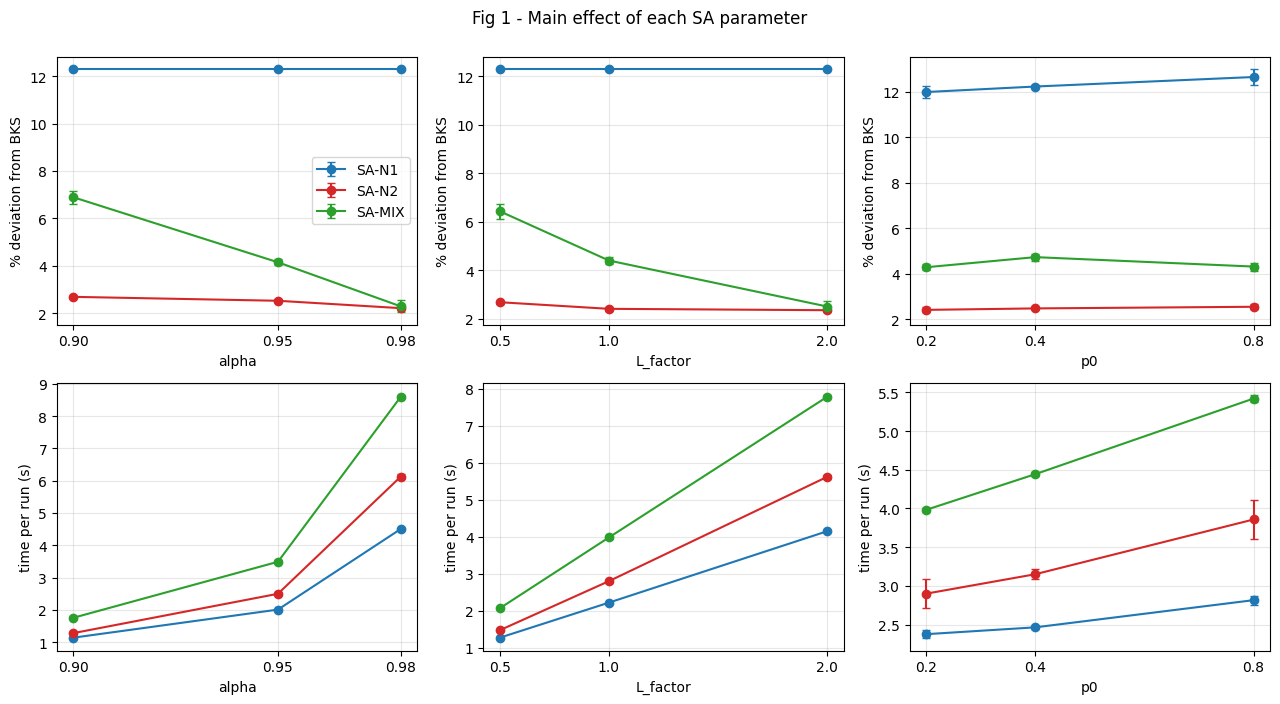

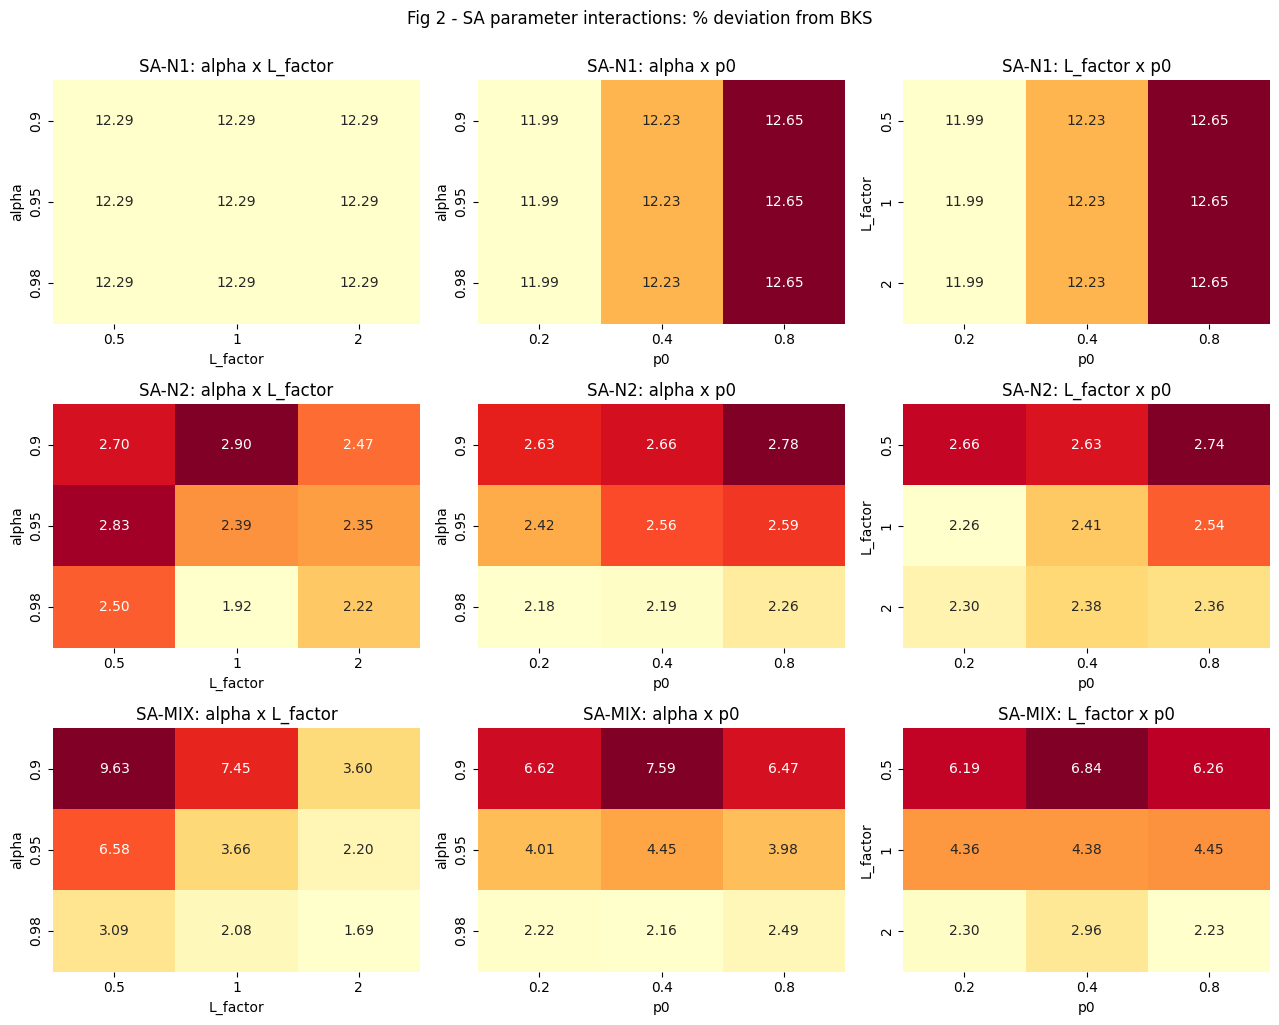

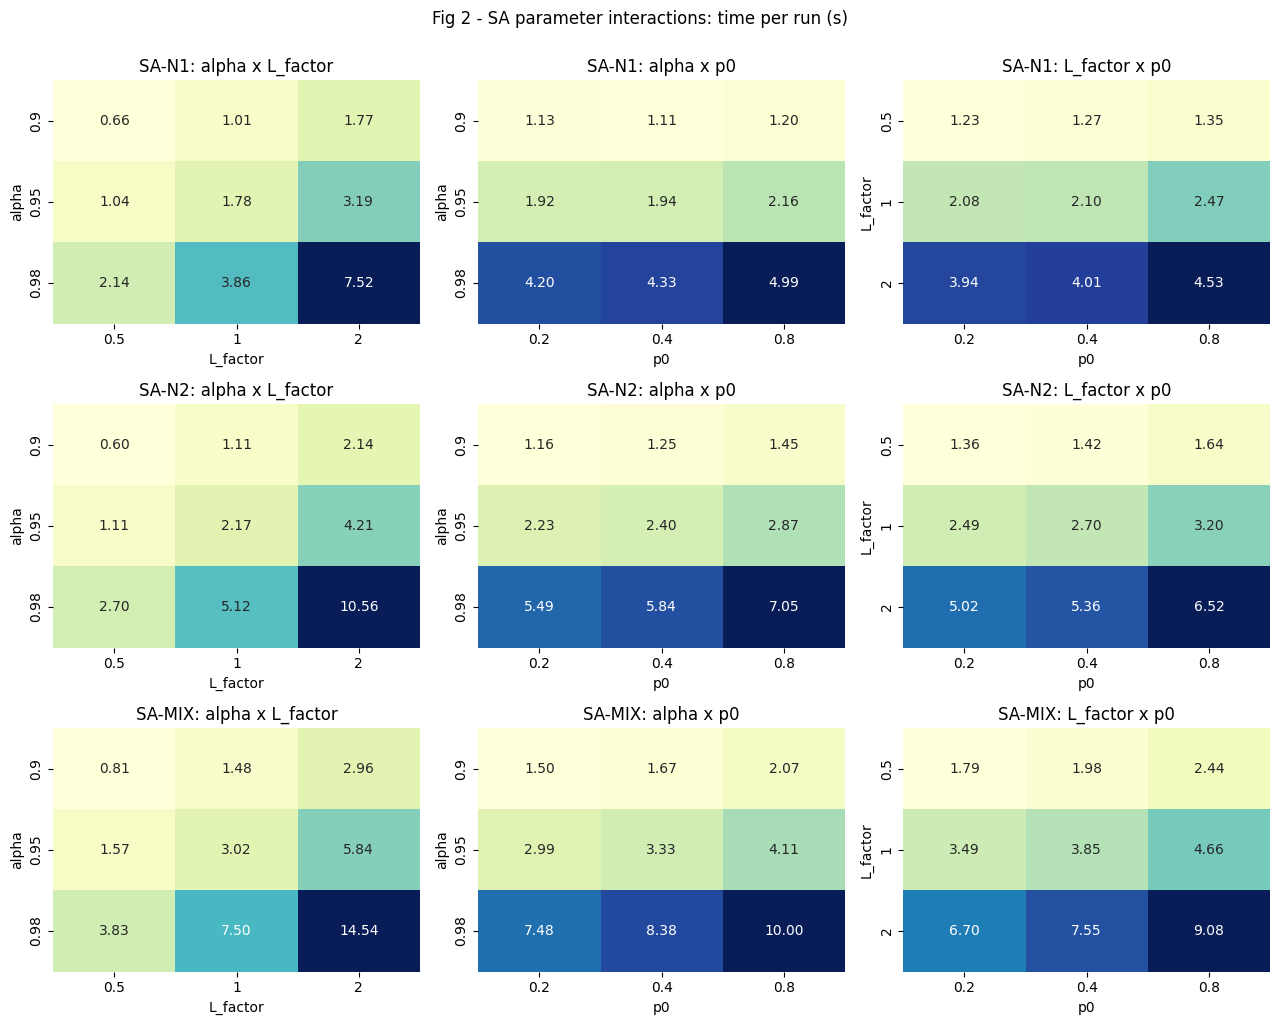

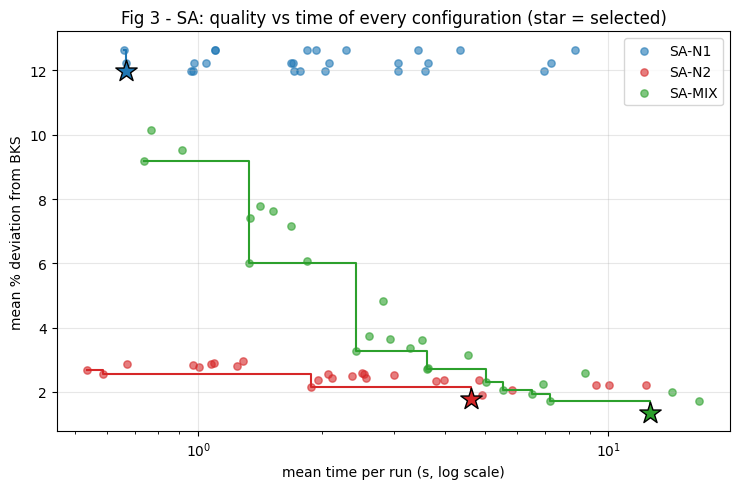

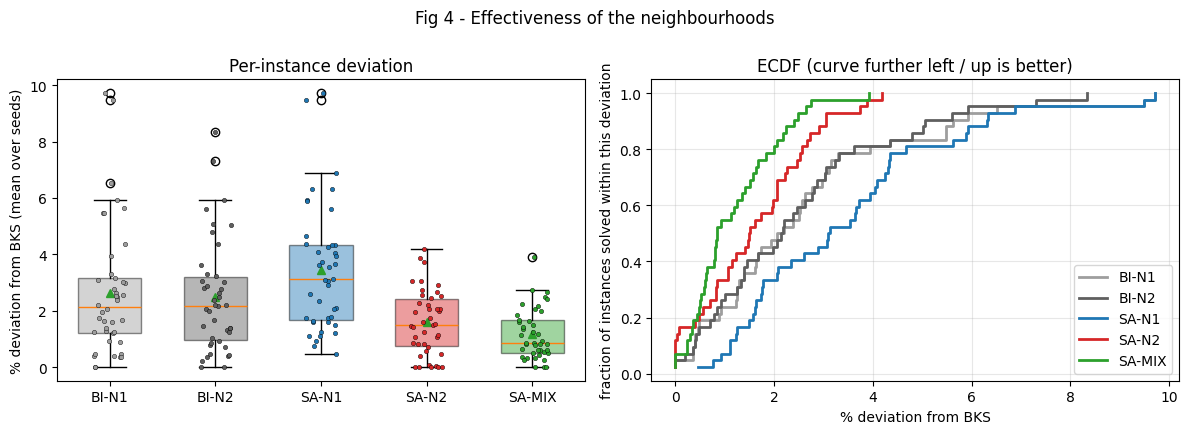

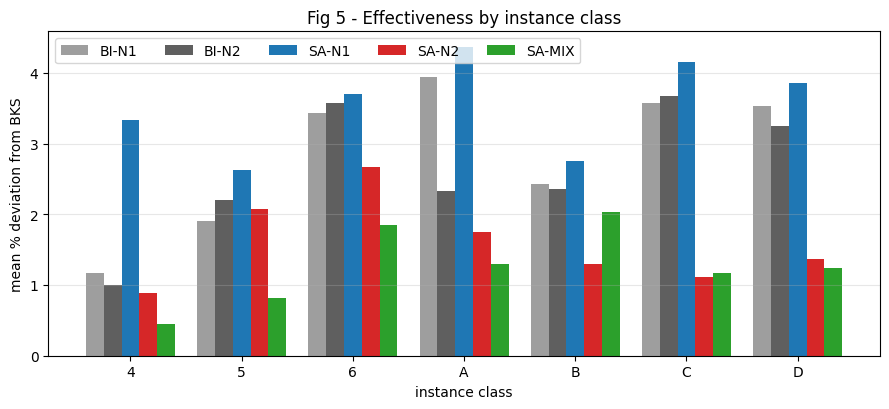

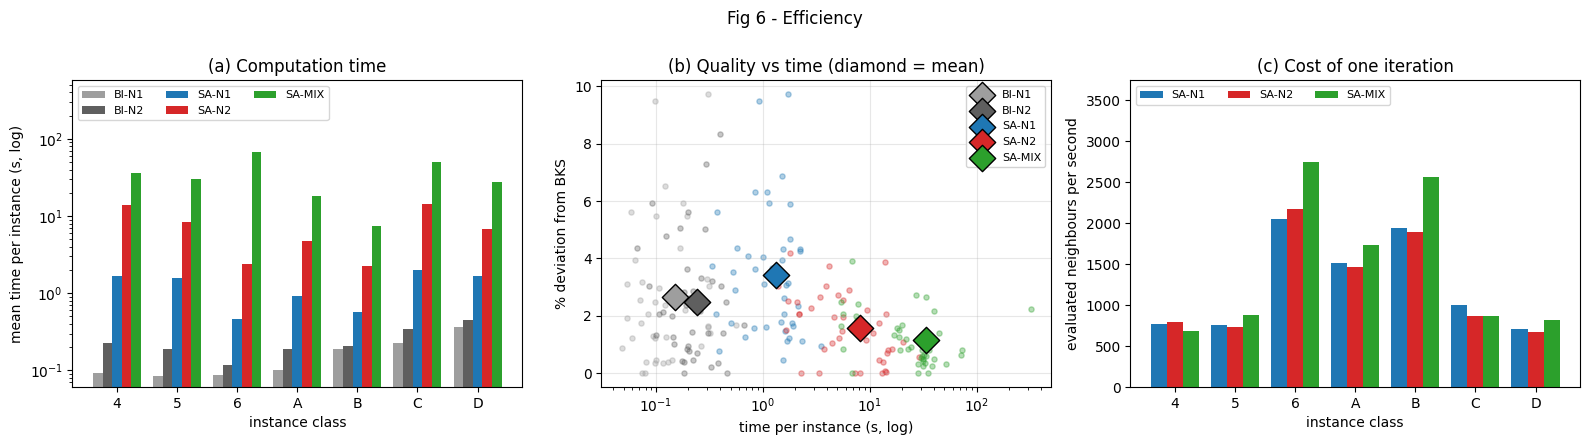

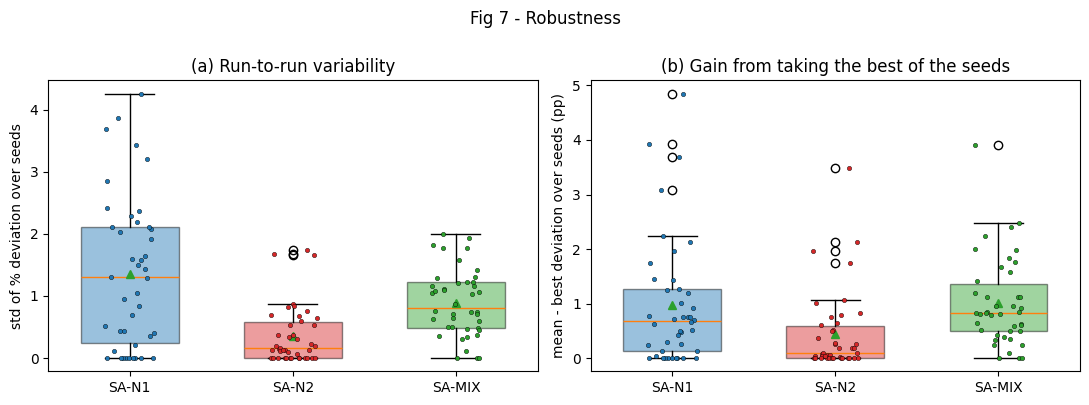

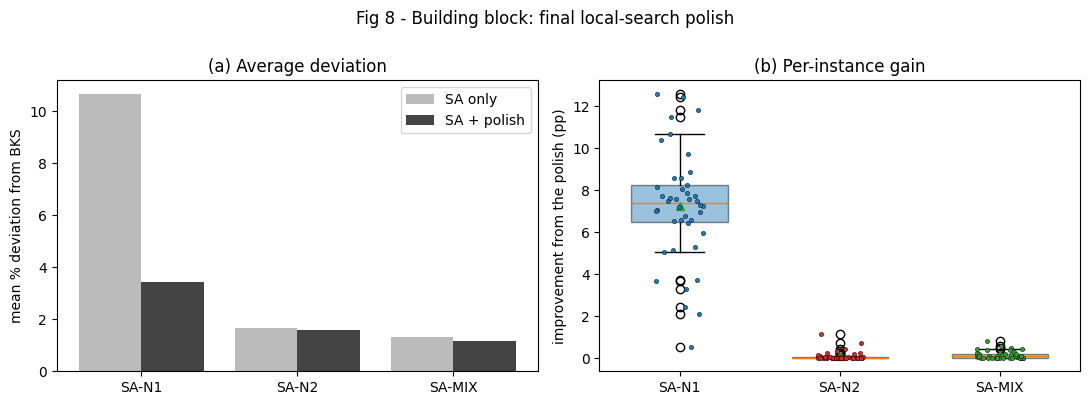

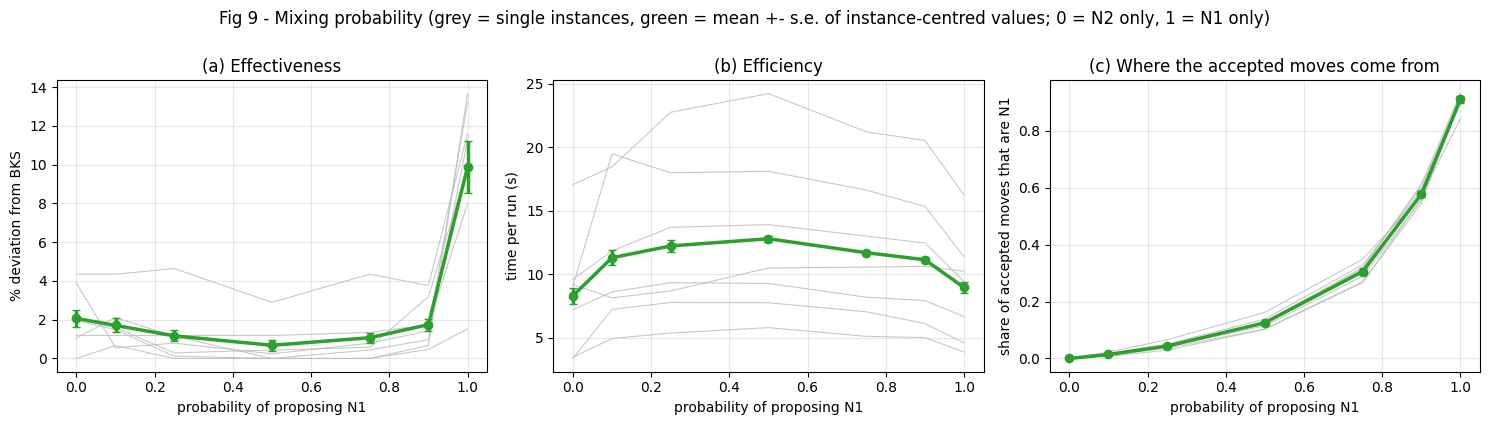

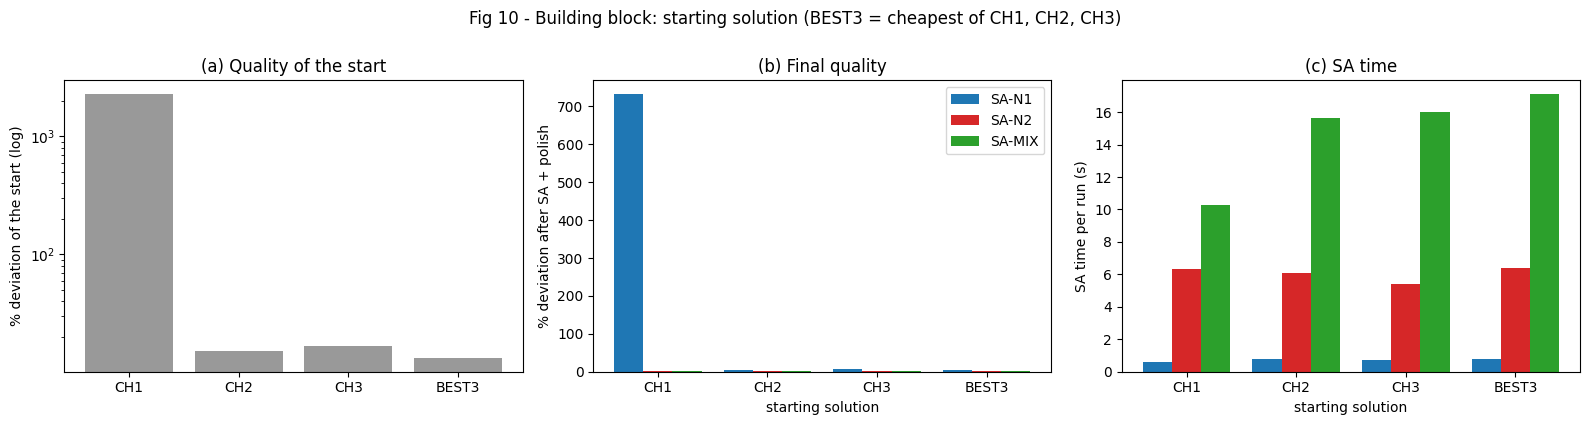

In [18]:
SAVE_FIGS = True              # figures are saved as PNG in ./figures

# E1 - influence of the cooling parameters (from the tuning experiment)
if df_tune is not None and len(df_tune):
    plot_main_effects(df_tune)
    plot_interactions(df_tune, "Pct_Dev", "fig2_interactions_dev")
    plot_interactions(df_tune, "Time_s", "fig2_interactions_time")
    plot_pareto(df_tune, best_params)

# E2, E5, E6 - neighbourhoods, robustness, polish, search dynamics (from the final experiment)
if df_sa is not None and len(df_sa):
    per_inst_all, _ = summarize_final(df_sa)
    plot_method_comparison(per_inst_all)
    plot_dev_by_class(per_inst_all)
    plot_efficiency(df_sa, per_inst_all)
    plot_robustness(per_inst_all)
    plot_polish_effect(per_inst_all)
    if sa_histories:
        plot_anytime(sa_histories, BKS, df_sa, x="time")
        plot_anytime(sa_histories, BKS, df_sa, x="evals")
        plot_acceptance(sa_histories, BKS)

# E3 / E4 - building blocks
if df_mix is not None and len(df_mix):
    plot_mix_sensitivity(df_mix)
if df_start is not None and len(df_start):
    plot_start_ablation(df_start)

## 11. Tabu Search

Tabu Search (TS) moves at every iteration to the **best admissible neighbour found, even if it is worse than the current solution**, and uses memory to avoid cycling and to diversify. It uses exactly the same starting solution, neighbourhoods (N1, N2, MIX with N1 90 % / N2 10 %), neighbour sampler and exact evaluation (including RE) as SA, so any difference between the two comes from the search strategy.

### 11.1 Components of the algorithm

| Feature | Definition in this implementation |
|---|---|
| Starting solution | cheapest of CH1, CH2, CH3 (same snapshot as SA) |
| Neighbourhoods | **N1** 1-1 swap + RE, **N2** remove one set + greedy repair + RE, **MIX**: every candidate is N1 with probability 0.9, otherwise N2 (N2 fallback if no feasible swap exists, as in SA-MIX) |
| Candidate list | at every iteration a **random sample of `cand = max(1, round(cand_factor * abs(S)))` neighbours** is generated with the same sampler as SA and evaluated exactly. A full scan of N1 (`abs(S) * n` pairs) is too expensive, so a candidate-list strategy is used; `cand_factor` is tuned (it trades breadth of the scan against the number of iterations for a fixed budget) |
| Move selection | the best admissible candidate is executed **even if it worsens the solution** |
| Tabu attribute and list | every set **removed** by an executed move (the swapped-out / removed set and the sets removed by RE) may not re-enter for `tenure` iterations. A candidate move is tabu if any set it adds is tabu. Recency is stored as `tabu_until[s]` |
| Tabu tenure | `tenure = max(1, round(tenure_factor * abs(S)))`, `tenure_factor` in {0.05, 0.1, 0.2}, tuned per neighbourhood (a relative tenure keeps the same meaning for small and large instances) |
| Aspiration | a tabu candidate is admissible if its exact cost is strictly below the **best cost found so far in this run** (not the literature BKS) |
| All candidates tabu | the best tabu candidate is executed, so the search never stalls |
| Long-term memory | **residence frequency**: `residence[s]` counts the iterations in which set `s` was part of the current solution; `freq = residence / iterations`. After `ltm_patience = 20` iterations without a new best, candidates are ranked by `cost + w * c_avg * (sum of freq of added sets - sum of freq of removed sets)`, with `w = ltm_weight = 0.3` and `c_avg` the average cost of a selected set. Adding sets that have been resident most of the time is penalised and dropping them is rewarded, which pushes the search to unexplored regions. The penalty only ranks candidates (aspiration and the incumbent use the true cost) and is switched off as soon as a new best is found |
| Stopping | **evaluation budget**: in the comparison TS gets the same number of evaluated neighbours as the SA run with the same instance, variant and seed (SA main loop + its 200 calibration evaluations). Stand-alone use: `max_iterations` and/or `time_limit` |
| Result | the best solution found (not the last one), improved by the same best-improvement polish as SA |

**Why the previous TS was not comparable to SA** (all fixed): it used 500 iterations of `abs(S)` samples (4-10 times more evaluations and time than SA) with no relation to SA's budget; it had no final polish while SA had one; the MIX draw was made once per iteration (and a failed N1 draw wasted the iteration) instead of per candidate; the long-term memory was always active, counted additions instead of residence and ignored the removed sets; the tenure was not tuned although the text said it was; and the text called the incumbent "BKS".

**Essential sets.** No explicit locking is needed: N1 only considers swaps whose entering set covers every critical element (elements covered only by the leaving set), and the N2 repair re-covers every element left uncovered, so every neighbour is feasible by construction.

### 11.2 Implementation

`tabu_search` returns the best cost before the polish (`ts_cost`) and after it (`final_cost`), the number of evaluated neighbours, the accepted moves per neighbourhood, how often aspiration and the all-tabu fallback were used, and a history sampled about 200 times per run (best-so-far against evaluations and time).

In [19]:
# ----------------------------------------------------------------------------
# Tabu Search: N1, N2 and MIX, with candidate list, tabu list, aspiration, residence-based LTM
# ----------------------------------------------------------------------------
TS_VARIANTS = {"TS-N1": "N1", "TS-N2": "N2", "TS-MIX": "MIX"}
SA_OF_TS = {"TS-N1": "SA-N1", "TS-N2": "SA-N2", "TS-MIX": "SA-MIX"}   # TS variant -> SA variant with the same neighbourhood
TS_P_N1 = P_N1                  # MIX: N1 with probability 0.9, N2 with probability 0.1 (same as SA)
TS_LTM_WEIGHT = 0.3             # weight of the residence penalty (relative to the mean cost of a selected set)
TS_LTM_PATIENCE = 20            # iterations without a new best before the long-term memory is switched on


def tabu_search(inst, mats, start_snapshot, variant="N2", seed=SEED,
                p_n1=TS_P_N1,                # MIX only: probability of proposing an N1 move
                tenure_factor=0.1,           # tabu tenure = tenure_factor * |S|           (tuned)
                cand_factor=0.5,             # candidate-list size = cand_factor * |S|      (tuned)
                use_aspiration=True,         # building block: aspiration criterion
                use_ltm=True,                # building block: residence-based long-term memory
                ltm_weight=TS_LTM_WEIGHT, ltm_patience=TS_LTM_PATIENCE,
                max_evaluations=None,        # budget: number of evaluated neighbours (the comparison uses SA's)
                max_iterations=None, time_limit=None,
                polish=True):                # final BI local search from the best solution (as in SA)
    """Tabu search for one variant ("N1", "N2" or "MIX"). Returns a dict with costs, statistics, history."""
    if max_evaluations is None and max_iterations is None and time_limit is None:
        raise ValueError("give at least one stopping criterion (max_evaluations, max_iterations or time_limit)")
    rng = np.random.default_rng(seed)
    t_start = time.perf_counter()

    inst.restore(start_snapshot)
    if not inst.is_complete_cover():
        raise ValueError("TS needs a feasible starting cover")
    start_cost = float(inst.solution_cost)
    sel = np.flatnonzero(inst.chosen)
    best_cost, best_sets = start_cost, sel.copy()

    tabu_until = np.full(inst.n, -1, dtype=np.int64)   # set s may not re-enter while tabu_until[s] >= iteration
    residence = np.zeros(inst.n, dtype=np.float64)     # iterations each set has spent in the solution

    history, used = [], {"N1": 0, "N2": 0}
    n_eval = it = no_improve = 0
    n_aspiration = n_forced = ltm_iters = 0
    rec_every = max(1, max_evaluations // 200) if max_evaluations else 1
    next_rec = 0

    while True:
        if max_evaluations is not None and n_eval >= max_evaluations:
            break
        if max_iterations is not None and it >= max_iterations:
            break
        if time_limit is not None and time.perf_counter() - t_start > time_limit:
            break

        n_cand = max(1, int(round(cand_factor * len(sel))))
        if max_evaluations is not None:
            n_cand = min(n_cand, max_evaluations - n_eval)          # never exceed the budget
        tenure = max(1, int(round(tenure_factor * len(sel))))

        ltm_on = use_ltm and no_improve >= ltm_patience
        if ltm_on:
            ltm_iters += 1
            freq = residence / max(1, it)
            scale = ltm_weight * inst.solution_cost / max(1, len(sel))

        best_adm = best_tabu = None                  # (score, move, kind, aspired)
        for _ in range(n_cand):
            mv, kind = sa_random_neighbor(inst, mats, rng, sel, variant, p_n1)
            n_eval += 1
            if mv is None:
                continue
            score = mv["cost"]
            if ltm_on:                                # diversification: only used to rank candidates
                score += scale * (freq[mv["add"]].sum() - freq[mv["remove"]].sum())
            tabu = any(tabu_until[s] >= it for s in mv["add"])
            aspired = False
            if tabu and use_aspiration and mv["cost"] < best_cost - EPS:
                tabu, aspired = False, True           # aspiration: beats the incumbent
            if not tabu:
                if best_adm is None or score < best_adm[0]:
                    best_adm = (score, mv, kind, aspired)
            elif best_tabu is None or score < best_tabu[0]:
                best_tabu = (score, mv, kind, False)

        chosen = best_adm
        if chosen is None and best_tabu is not None:      # every candidate tabu: take the best one
            chosen, n_forced = best_tabu, n_forced + 1
        if chosen is not None:
            _, mv, kind, aspired = chosen
            apply_move(inst, mv)
            if abs(inst.solution_cost - mv["cost"]) > 1e-6:
                raise AssertionError("move cost mismatch")
            used[kind] += 1
            n_aspiration += int(aspired)
            sel = np.flatnonzero(inst.chosen)
            for s in mv["remove"]:                        # recency memory
                tabu_until[s] = it + tenure
        residence[sel] += 1                               # long-term (residence) memory

        if inst.solution_cost < best_cost - EPS:
            best_cost, best_sets = float(inst.solution_cost), sel.copy()
            no_improve = 0
        else:
            no_improve += 1
        it += 1
        if n_eval >= next_rec:
            history.append({"iteration": it, "evals": n_eval, "time": time.perf_counter() - t_start,
                            "current": float(inst.solution_cost), "best": best_cost})
            next_rec = n_eval + rec_every

    if not history or history[-1]["evals"] != n_eval:
        history.append({"iteration": it, "evals": n_eval, "time": time.perf_counter() - t_start,
                        "current": float(inst.solution_cost), "best": best_cost})

    # ---- rebuild the best solution found, optionally polish it (same polish as SA)
    inst.reset()
    for j in best_sets:
        inst.add_set(int(j))
    inst.check_solution()
    ts_cost = float(inst.solution_cost)
    polish_moves = polish_solution(inst, mats, variant) if polish else 0

    return {
        "start_cost": start_cost, "ts_cost": ts_cost, "final_cost": float(inst.solution_cost),
        "evaluations": n_eval, "iterations": it, "ltm_iterations": ltm_iters,
        "accepted_N1": used["N1"], "accepted_N2": used["N2"],
        "aspiration_moves": n_aspiration, "forced_tabu_moves": n_forced,
        "polish_moves": polish_moves, "time_s": time.perf_counter() - t_start,
        "history": history,
    }

### 11.3 Parameter tuning of TS

Same philosophy as for SA: each TS variant is tuned separately with a **full factorial design**.

| Factor | Levels | Meaning |
|---|---|---|
| `tenure_factor` | 0.05, 0.1, 0.2 | tabu tenure = `tenure_factor * abs(S)` iterations |
| `cand_factor` | 0.25, 0.5, 1.0 | candidate-list size = `cand_factor * abs(S)` sampled neighbours per iteration |

`ltm_weight = 0.3`, `ltm_patience = 20` and the use of aspiration and long-term memory are fixed here; the two building blocks are isolated in the ablation of section 11.4.

* **Budget.** For a fixed number of evaluations a larger candidate list means fewer iterations, so the budget must be the same for all configurations. In the tuning every run receives the **mean number of evaluations of the SA configuration selected in 9.2** for the same instance and variant (+ 200 calibration evaluations), i.e. the budget of the final comparison.
* **Instances and seeds.** The same 7 tuning instances (one per class) and 3 seeds as for SA; no final polish, so the tuning measures TS itself.
* **Analysis.** Same as for SA (`analyze_tuning`): ranking of the 9 configurations, main effects, Friedman test; the configuration with the lowest mean deviation is selected per variant.

In [20]:
# ----------------------------------------------------------------------------
# TS parameter tuning (full factorial, each TS variant tuned separately)
# ----------------------------------------------------------------------------
TS_GRID = {
    "tenure_factor": [0.05, 0.1, 0.2],      # tabu tenure = tenure_factor * |S|
    "cand_factor":   [0.25, 0.5, 1.0],      # candidate list = cand_factor * |S| sampled neighbours
}
DEFAULT_TS_PARAMS = {"tenure_factor": 0.1, "cand_factor": 0.5}
TS_TUNE_CSV = "scp_ts_tuning.csv"
TS_TUNE_SEEDS = range(3)


def sa_budget_from_tuning(df_tune, best_params):
    """{(instance, SA variant): evaluations} = mean evaluations of the SA configuration selected in 9.2
    (+ the calibration evaluations), measured on the tuning runs."""
    budgets = {}
    for vname, params in best_params.items():
        d = df_tune[df_tune["Variant"] == vname]
        for f, val in params.items():
            d = d[np.isclose(d[f], val)]
        for label, g in d.groupby("Instance"):
            budgets[(label, vname)] = int(round(g["Evaluations"].mean())) + SA_N_CALIB
    return budgets


def run_ts_tuning(instances, bks_dict, initial_solutions_data, labels, budgets, variants=TS_VARIANTS,
                  grid=None, seeds=range(3), csv_path=TS_TUNE_CSV):
    """Every (variant, configuration, instance, seed) combination; TS WITHOUT polish; common random numbers."""
    grid = TS_GRID if grid is None else grid
    configs = [dict(zip(grid, vals)) for vals in itertools.product(*grid.values())]
    seeds = list(seeds)
    print(f"{len(configs)} configurations x {len(variants)} variants x {len(labels)} instances "
          f"x {len(seeds)} seeds = {len(configs) * len(variants) * len(labels) * len(seeds)} TS runs")
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        snap = best_constructive_start(initial_solutions_data[label])[2]
        for vname, variant in variants.items():
            budget = budgets[(label, SA_OF_TS[vname])]
            for cfg in configs:
                for seed in seeds:
                    r = tabu_search(inst, mats, snap, variant=variant, seed=seed, polish=False,
                                    max_evaluations=budget, **cfg)
                    records.append({"Instance": label, "Variant": vname, **cfg, "Seed": seed,
                                    "TS_Cost": r["ts_cost"], "Pct_Dev": 100 * (r["ts_cost"] - bks) / bks,
                                    "Time_s": r["time_s"], "Evaluations": r["evaluations"],
                                    "Iterations": r["iterations"]})
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] TS tuning finished {label}", flush=True)
    return pd.DataFrame(records)


if instances and initial_solutions_data and df_tune is not None:
    ts_budgets = sa_budget_from_tuning(df_tune, best_params)
    ts_tune_labels = tune_labels
    df_ts_tune = None
    if can_reuse(TS_TUNE_CSV, "ts_tuning"):
        df_ts_tune = pd.read_csv(TS_TUNE_CSV)
        if grid_matches(df_ts_tune, TS_GRID) and set(df_ts_tune["Instance"]) == set(ts_tune_labels):
            print(f"Loaded cached TS tuning data from {TS_TUNE_CSV}")
        else:
            print("Cached TS tuning data does not match the current settings -> recomputing")
            df_ts_tune = None
    if df_ts_tune is None:
        df_ts_tune = run_ts_tuning(instances, BKS, initial_solutions_data, ts_tune_labels, ts_budgets,
                                   seeds=TS_TUNE_SEEDS)
    best_ts_params = analyze_tuning(df_ts_tune, grid=TS_GRID)
else:
    ts_tune_labels, df_ts_tune = [], None
    best_ts_params = {v: DEFAULT_TS_PARAMS for v in TS_VARIANTS}
    print("No tuning data available: default TS parameters are used.")

9 configurations x 3 variants x 7 instances x 3 seeds = 567 TS runs
[   431.7s] TS tuning finished 4.2
[   917.4s] TS tuning finished 5.1
[  1108.8s] TS tuning finished 6.1
[  1650.5s] TS tuning finished A.1
[  1882.7s] TS tuning finished B.1
[  2679.0s] TS tuning finished C.1
[  2994.7s] TS tuning finished D.1
TS-N1
Top 8 configurations:


,,Mean_%dev,Mean_time_s,Mean_evals
tenure_factor,cand_factor,,,
0.20,1.00,6.701,0.527,1207.857
0.05,1.00,6.701,0.533,1207.857
0.10,1.00,6.701,0.566,1207.857
0.20,0.50,8.615,0.528,1207.857
0.10,0.50,8.615,0.544,1207.857
0.05,0.50,8.615,0.550,1207.857
0.20,0.25,9.329,0.520,1207.857
0.10,0.25,9.329,0.537,1207.857


Main effect of tenure_factor:


,Pct_Dev,Time_s
tenure_factor,,
0.05,8.215,0.555
0.10,8.215,0.549
0.20,8.215,0.525


Main effect of cand_factor:


...

Main effect of tenure_factor:


,Pct_Dev,Time_s
tenure_factor,,
0.05,3.840,11.082
0.10,4.619,11.061
0.20,5.162,11.027


Main effect of cand_factor:


,Pct_Dev,Time_s
cand_factor,,
0.25,6.462,10.994
0.50,4.743,11.105
1.00,2.416,11.071


Friedman test across 9 configurations (7 instances): chi2 = 52.98, p = 1.088e-08
-> selected: {'tenure_factor': 0.05, 'cand_factor': 1.0} 



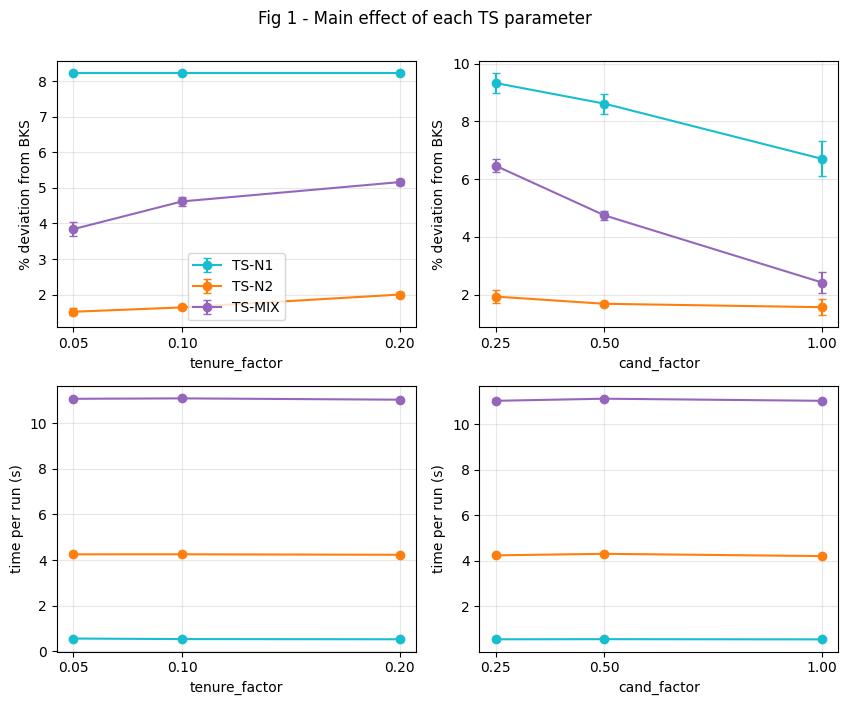

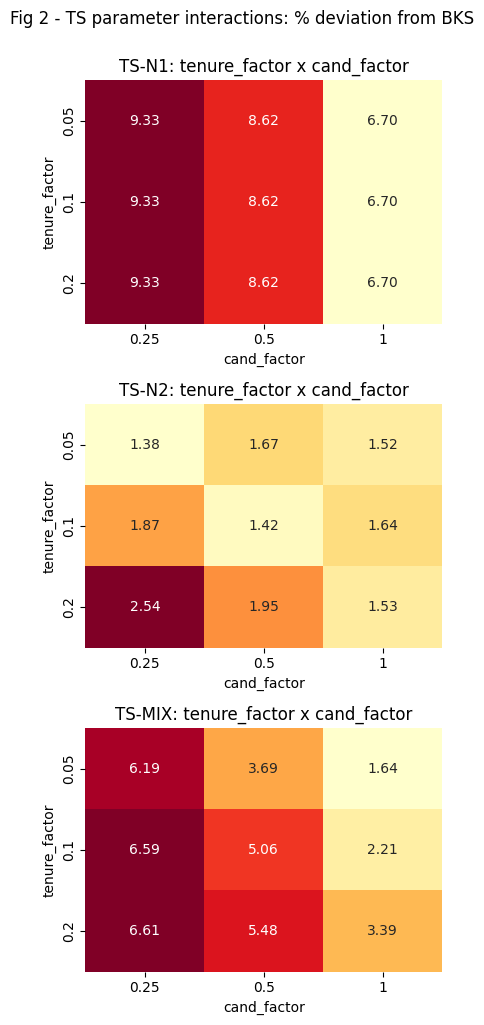

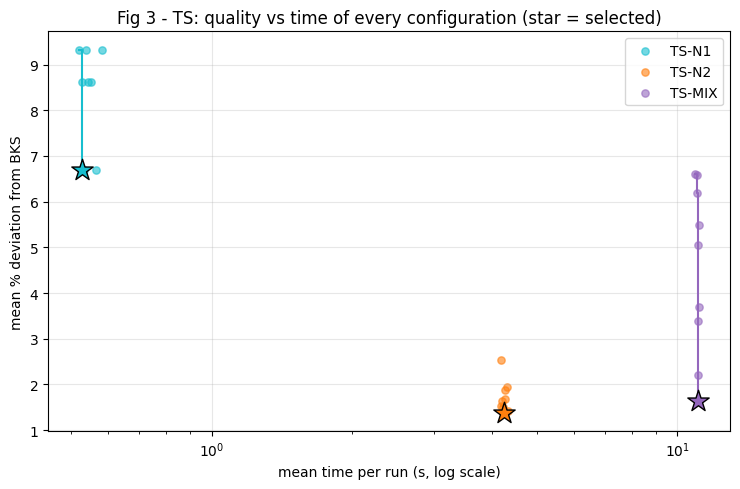

In [21]:
# ---- Figures for the TS tuning (same helpers as for SA) -----------------------------
if df_ts_tune is not None and len(df_ts_tune):
    plot_main_effects(df_ts_tune, grid=TS_GRID, algo="TS", prefix="ts_")
    plot_interactions(df_ts_tune, "Pct_Dev", "fig2_interactions_dev", grid=TS_GRID, algo="TS", prefix="ts_")
    plot_pareto(df_ts_tune, best_ts_params, grid=TS_GRID, algo="TS", prefix="ts_")

### 11.4 Building-block ablation: aspiration and long-term memory

With the tuned `tenure_factor` and `cand_factor` of each variant, four configurations are run on the tuning instances (3 variants x 7 instances x 5 seeds, same evaluation budgets as above, no final polish):

| Configuration | Aspiration | Long-term memory |
|---|---|---|
| No Asp, No LTM | off | off |
| Asp Only | on | off |
| LTM Only | off | on |
| Full TS | on | on |

The response is the % deviation from the BKS and the time. The number of executed aspiration moves and of iterations with the long-term memory active is reported, to show whether the block was actually used. Differences between configurations are tested per variant with paired Wilcoxon tests on the per-instance means (Full TS and the single-block configurations against the plain tabu list).

[   320.0s] TS ablation finished 4.2
[   678.0s] TS ablation finished 5.1
[   820.9s] TS ablation finished 6.1
[  1221.1s] TS ablation finished A.1
[  1390.3s] TS ablation finished B.1
[  1982.3s] TS ablation finished C.1
[  2213.8s] TS ablation finished D.1
=== TS ablation: mean % deviation from BKS (rows: configuration, columns: variant) ===


Variant,TS-N1,TS-N2,TS-MIX
Config,,,
"No Asp, No LTM",6.335,1.750,1.426
Asp Only,6.205,1.408,1.434
LTM Only,6.335,1.431,1.805
Full TS,6.205,1.365,1.761


=== mean time per run (s) ===


Variant,TS-N1,TS-N2,TS-MIX
Config,,,
"No Asp, No LTM",0.562,4.253,10.950
Asp Only,0.553,4.213,10.928
LTM Only,0.542,4.223,11.158
Full TS,0.525,4.243,11.096


=== use of the building blocks (mean per run) ===


Aspiration_moves  LTM_iterations  Forced_tabu_moves
Config         Variant                                                     
Asp Only       TS-MIX                0.9             0.0                0.0
               TS-N1                 0.2             0.0                0.0
               TS-N2                 1.2             0.0                0.1
Full TS        TS-MIX                1.1           399.1                0.0
               TS-N1                 0.2             1.3                0.0
               TS-N2                 1.3           497.1                0.1
LTM Only       TS-MIX                0.0           399.6                0.0
               TS-N1                 0.0             1.5                0.0
               TS-N2                 0.0           490.0                0.1
No Asp, No LTM TS-MIX                0.0             0.0                0.0
               TS-N1                 0.0             0.0                0.0
               TS-N2                 0.0             0.0                0.0

=== paired Wilcoxon tests against the plain tabu list (per-instance means) ===


,Variant,Config,vs,mean_dev,mean_dev_ref,better on,worse on,ties,Wilcoxon p
0,TS-N1,Asp Only,"No Asp, No LTM",6.2048,6.3346,3,0,4,0.2500
1,TS-N1,LTM Only,"No Asp, No LTM",6.3346,6.3346,0,0,7,1.0000
2,TS-N1,Full TS,"No Asp, No LTM",6.2048,6.3346,3,0,4,0.2500
3,TS-N2,Asp Only,"No Asp, No LTM",1.4082,1.7501,5,0,2,0.0625
4,TS-N2,LTM Only,"No Asp, No LTM",1.4314,1.7501,3,3,1,0.9062
5,TS-N2,Full TS,"No Asp, No LTM",1.3653,1.7501,4,2,1,0.8438
6,TS-MIX,Asp Only,"No Asp, No LTM",1.4339,1.4264,3,2,2,1.0000
7,TS-MIX,LTM Only,"No Asp, No LTM",1.8046,1.4264,1,5,1,0.0938
8,TS-MIX,Full TS,"No Asp, No LTM",1.7611,1.4264,2,5,0,0.0781


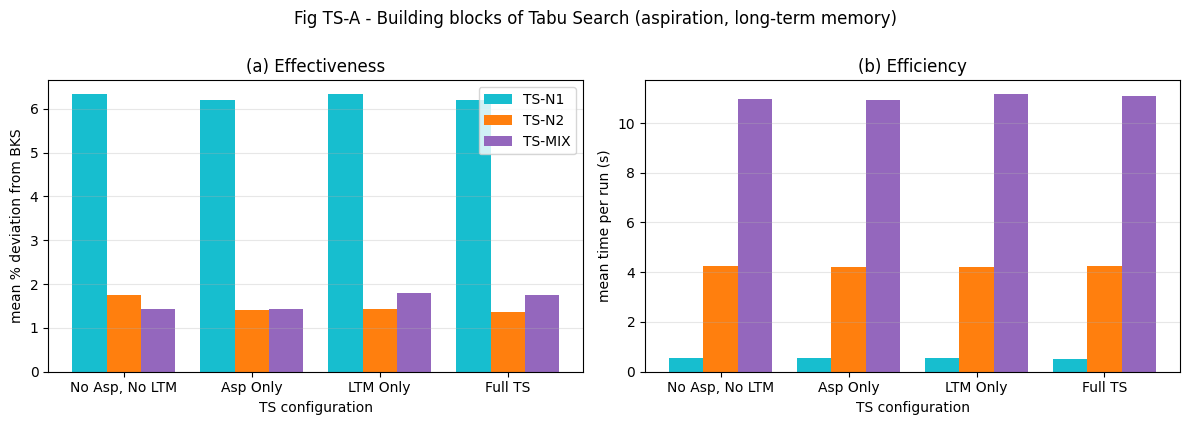

In [22]:
# ----------------------------------------------------------------------------
# TS building-block ablation (aspiration, long-term memory)
# ----------------------------------------------------------------------------
TS_ABL_CSV = "scp_ts_ablation.csv"
TS_ABL_SEEDS = range(5)
TS_ABL_CONFIGS = [("No Asp, No LTM", False, False), ("Asp Only", True, False),
                  ("LTM Only", False, True), ("Full TS", True, True)]


def run_ts_ablation(instances, bks_dict, initial_solutions_data, labels, budgets, params_per_variant,
                    seeds=range(5), csv_path=TS_ABL_CSV):
    records, t_all = [], time.perf_counter()
    for label in labels:
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        snap = best_constructive_start(initial_solutions_data[label])[2]
        for vname, variant in TS_VARIANTS.items():
            budget = budgets[(label, SA_OF_TS[vname])]
            params = params_per_variant.get(vname, DEFAULT_TS_PARAMS)
            for conf_name, asp, ltm in TS_ABL_CONFIGS:
                for seed in seeds:
                    r = tabu_search(inst, mats, snap, variant=variant, seed=seed, polish=False,
                                    use_aspiration=asp, use_ltm=ltm, max_evaluations=budget, **params)
                    records.append({"Instance": label, "Variant": vname, "Config": conf_name, "Seed": seed,
                                    "Pct_Dev": 100 * (r["ts_cost"] - bks) / bks, "Time_s": r["time_s"],
                                    "Evaluations": r["evaluations"], "Iterations": r["iterations"],
                                    "Aspiration_moves": r["aspiration_moves"],
                                    "LTM_iterations": r["ltm_iterations"],
                                    "Forced_tabu_moves": r["forced_tabu_moves"]})
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] TS ablation finished {label}", flush=True)
    return pd.DataFrame(records)


def analyze_ts_ablation(df):
    """Mean deviation / time per configuration and variant, usage of the blocks, paired Wilcoxon tests."""
    order = [c[0] for c in TS_ABL_CONFIGS]
    variants = [v for v in TS_VARIANTS if v in set(df["Variant"])]
    dev = df.groupby(["Config", "Variant"])["Pct_Dev"].mean().unstack().reindex(order)[variants]
    tim = df.groupby(["Config", "Variant"])["Time_s"].mean().unstack().reindex(order)[variants]
    use = df.groupby(["Config", "Variant"])[["Aspiration_moves", "LTM_iterations", "Forced_tabu_moves"]].mean()
    rows = []
    for v in variants:
        per = df[df["Variant"] == v].groupby(["Instance", "Config"])["Pct_Dev"].mean().unstack()
        for c in order[1:]:
            d = (per[c] - per[order[0]]).dropna()
            try:
                p = wilcoxon(per[c], per[order[0]]).pvalue if (d != 0).any() else 1.0
            except ValueError:
                p = float("nan")
            rows.append({"Variant": v, "Config": c, "vs": order[0], "mean_dev": per[c].mean(),
                         "mean_dev_ref": per[order[0]].mean(), "better on": int((d < 0).sum()),
                         "worse on": int((d > 0).sum()), "ties": int((d == 0).sum()), "Wilcoxon p": p})
    return dev, tim, use, pd.DataFrame(rows)


def plot_ts_ablation(df):
    order = [c[0] for c in TS_ABL_CONFIGS]
    variants = [v for v in TS_VARIANTS if v in set(df["Variant"])]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for k, (col, ylab) in enumerate([("Pct_Dev", "mean % deviation from BKS"), ("Time_s", "mean time per run (s)")]):
        t = df.groupby(["Config", "Variant"])[col].mean().unstack().reindex(order)[variants]
        _grouped_bars(ax[k], t, PALETTE, ylab)
        ax[k].set_xlabel("TS configuration"); ax[k].grid(axis="y", alpha=0.3)
    ax[0].legend(); ax[0].set_title("(a) Effectiveness"); ax[1].set_title("(b) Efficiency")
    fig.suptitle("Fig TS-A - Building blocks of Tabu Search (aspiration, long-term memory)", y=1.0)
    _finish(fig, "ts_figA_ablation")


if instances and initial_solutions_data and df_ts_tune is not None:
    df_ts_abl = None
    if can_reuse(TS_ABL_CSV, "ts_ablation"):
        df_ts_abl = pd.read_csv(TS_ABL_CSV)
        if set(df_ts_abl["Instance"]) == set(ts_tune_labels) and set(df_ts_abl["Seed"]) == set(TS_ABL_SEEDS):
            print(f"Loaded cached TS ablation data from {TS_ABL_CSV}")
        else:
            print("Cached TS ablation data does not match the current settings -> recomputing")
            df_ts_abl = None
    if df_ts_abl is None:
        df_ts_abl = run_ts_ablation(instances, BKS, initial_solutions_data, ts_tune_labels, ts_budgets,
                                    best_ts_params, seeds=TS_ABL_SEEDS)
    dev, tim, use, tests = analyze_ts_ablation(df_ts_abl)
    print("=== TS ablation: mean % deviation from BKS (rows: configuration, columns: variant) ===")
    display(dev.round(3))
    print("=== mean time per run (s) ===")
    display(tim.round(3))
    print("=== use of the building blocks (mean per run) ===")
    display(use.round(1))
    print("=== paired Wilcoxon tests against the plain tabu list (per-instance means) ===")
    display(tests.round(4))
    plot_ts_ablation(df_ts_abl)
else:
    df_ts_abl = None
    print("Skipped: no tuning data available.")

## 12. Final TS experiment and comparison with SA under an identical evaluation budget

### 12.1 Final TS runs

The three TS variants, with the parameters selected in 11.3, are run on **all instances with seeds 0-9**. The run of TS-X with seed *s* on instance *i* receives **exactly the number of evaluated neighbours of the run of SA-X with seed *s* on *i*** (SA main loop + 200 calibration evaluations), starts from the same snapshot and is followed by the same polish. Hence the comparison is paired (same instance, same neighbourhood, same seed index, same budget) and any difference in cost is due to the search strategy. The measured times are reported separately: they differ only if a neighbour evaluation is cheaper in one of the methods. Raw results are saved in `scp_ts_results.csv`, histories in `scp_ts_histories.pkl`.

In [23]:
# ----------------------------------------------------------------------------
# Final TS experiment: same instances, seeds, start, polish and evaluation budget as SA
# ----------------------------------------------------------------------------
TS_CSV, TS_HIST_PKL = "scp_ts_results.csv", "scp_ts_histories.pkl"


def sa_eval_lookup(df_sa):
    """{(instance, SA method, seed): evaluations of that SA run + calibration evaluations}."""
    d = df_sa[df_sa["Method"].isin(SA_VARIANTS) & df_sa["Seed"].notna()]
    return {(r.Instance, r.Method, int(r.Seed)): int(r.Evaluations) + SA_N_CALIB for r in d.itertuples()}


def run_ts_final(instances, bks_dict, initial_solutions_data, df_sa, params_per_variant,
                 seeds=range(10), labels=None, csv_path=TS_CSV):
    """TS with the budget of the SA run that has the same instance, variant and seed."""
    budgets = sa_eval_lookup(df_sa)
    records, histories = [], {}
    labels = sorted(set(df_sa["Instance"]), key=sort_key) if labels is None else labels
    t_all = time.perf_counter()
    for label in labels:
        if label not in bks_dict or label not in initial_solutions_data:
            continue
        inst, bks = instances[label], float(bks_dict[label])
        mats = build_matrices(inst)
        start_name, start_cost, snap, constr_time = best_constructive_start(initial_solutions_data[label])
        base = {"Instance": label, "Start": start_name, "Init_Cost": start_cost, "BKS": bks}
        for vname, variant in TS_VARIANTS.items():
            params = params_per_variant.get(vname, DEFAULT_TS_PARAMS)
            for seed in seeds:
                budget = budgets[(label, SA_OF_TS[vname], seed)]
                r = tabu_search(inst, mats, snap, variant=variant, seed=seed, polish=True,
                                max_evaluations=budget, **params)
                records.append({**base, "Method": vname, "Seed": seed,
                                "TS_Cost": r["ts_cost"], "Final_Cost": r["final_cost"],
                                "Pct_Dev": 100 * (r["final_cost"] - bks) / bks,
                                "Pct_Dev_noPolish": 100 * (r["ts_cost"] - bks) / bks,
                                "Evaluations": r["evaluations"], "Budget": budget,
                                "Iterations": r["iterations"], "LTM_iterations": r["ltm_iterations"],
                                "Accepted_N1": r["accepted_N1"], "Accepted_N2": r["accepted_N2"],
                                "Aspiration_moves": r["aspiration_moves"],
                                "Forced_tabu_moves": r["forced_tabu_moves"],
                                "TS_Time_s": r["time_s"], "Time_s": constr_time + r["time_s"], **params})
                histories[(vname, label, seed)] = r["history"]
        pd.DataFrame(records).to_csv(csv_path, index=False)
        print(f"[{time.perf_counter() - t_all:8.1f}s] TS final finished {label}", flush=True)
    return pd.DataFrame(records), histories


if instances and initial_solutions_data and df_sa is not None:
    ts_labels = sorted(set(df_sa["Instance"]), key=sort_key)
    df_ts = None
    if can_reuse(TS_CSV, "ts_final") and Path(TS_HIST_PKL).exists():
        df_ts = pd.read_csv(TS_CSV)
        if _cache_covers(df_ts, ts_labels, SA_SEEDS, list(TS_VARIANTS)):
            ts_histories = pickle.load(open(TS_HIST_PKL, "rb"))
            print(f"Loaded cached TS results ({len(df_ts)} runs) and histories.")
        else:
            print("Cached TS results do not cover the SA instances/seeds -> recomputing")
            df_ts = None
    if df_ts is None:
        df_ts, ts_histories = run_ts_final(instances, BKS, initial_solutions_data, df_sa, best_ts_params,
                                           seeds=SA_SEEDS, labels=ts_labels)
        pickle.dump(ts_histories, open(TS_HIST_PKL, "wb"))

    # unified data set: BI baselines + SA + TS
    df_combined = pd.concat([df_sa, df_ts], ignore_index=True)

    # the comparison is only valid if both methods used the same number of evaluations
    lookup = sa_eval_lookup(df_sa)
    expected = np.array([lookup[(r.Instance, SA_OF_TS[r.Method], int(r.Seed))] for r in df_ts.itertuples()])
    assert (df_ts["Evaluations"].values == expected).all(), "TS and SA runs do not have the same budget"
    print("Budget check passed: every TS run used exactly the evaluations of its matching SA run (+ calibration).")
else:
    df_ts, ts_histories, df_combined = None, {}, None
    print("Skipped: no SA results available.")

[   157.6s] TS final finished 4.2
[   326.4s] TS final finished 4.3
[   504.9s] TS final finished 4.4
[   650.2s] TS final finished 4.5
[   826.5s] TS final finished 4.6
[  1009.4s] TS final finished 4.7
[  1190.0s] TS final finished 4.8
[  1328.5s] TS final finished 4.9
[  1504.0s] TS final finished 5.1
[  1646.4s] TS final finished 5.2
[  1779.9s] TS final finished 5.3
[  1943.2s] TS final finished 5.4
[  2116.1s] TS final finished 5.5
[  2260.6s] TS final finished 5.6
[  2425.7s] TS final finished 5.7
[  2615.3s] TS final finished 5.8
[  2764.8s] TS final finished 5.9
[  2836.4s] TS final finished 6.1
[  2905.5s] TS final finished 6.2
[  2979.2s] TS final finished 6.3
[  3049.6s] TS final finished 6.4
[  3123.7s] TS final finished 6.5
[  3335.0s] TS final finished A.1
[  3544.4s] TS final finished A.2
[  3770.2s] TS final finished A.3
[  3990.4s] TS final finished A.4
[  4186.7s] TS final finished A.5
[  4270.7s] TS final finished B.1
[  4379.9s] TS final finished B.2
[  4470.6s] TS

### 12.2 Effectiveness and efficiency tables (SA vs TS)

* **Overall table:** average % deviation (mean over seeds and best of seeds), number of instances where the BKS is reached, std over seeds, total time, average evaluations (search loop only) for all methods (BI baselines, SA, TS).
* **Matched-pair table:** for each neighbourhood, SA-X against TS-X on the per-instance mean deviation (paired Wilcoxon test, Holm correction over the three neighbourhoods), plus the ratio of times and of evaluations. The ratio of evaluations is 1 by construction (up to the 200 calibration evaluations); the ratio of times shows the relative cost of the two search strategies.
* **Held-out instances** (those not used for tuning) are reported separately, since the parameters were tuned on the tuning instances.

In [24]:
def _holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj, run = np.empty(len(p)), 0.0
    for k, idx in enumerate(order):
        run = max(run, (len(p) - k) * p[idx])
        adj[idx] = min(1.0, run)
    return adj


def sa_vs_ts_table(df_cmp, exclude=()):
    """Matched comparison SA-X vs TS-X (X = N1, N2, MIX) on the per-instance mean % deviation."""
    d = df_cmp[~df_cmp["Instance"].isin(exclude)]
    per_inst, _ = summarize_final(d)
    dev = per_inst.pivot(index="Instance", columns="Method", values="Dev_mean")
    tim = per_inst.pivot(index="Instance", columns="Method", values="Time_s")
    ev = d.groupby(["Instance", "Method"])["Evaluations"].mean().unstack()
    rows = []
    for nb in ("N1", "N2", "MIX"):
        a, b = f"SA-{nb}", f"TS-{nb}"
        if a not in dev or b not in dev:
            continue
        diff = (dev[a] - dev[b]).dropna()
        try:
            p = wilcoxon(dev[a], dev[b]).pvalue if (diff.abs() > 1e-9).any() else 1.0
        except ValueError:
            p = float("nan")
        rows.append({"Neighbourhood": nb, "n instances": len(diff),
                     "mean dev SA": dev[a].mean(), "mean dev TS": dev[b].mean(),
                     "SA better on": int((diff < -1e-9).sum()), "TS better on": int((diff > 1e-9).sum()),
                     "ties": int((diff.abs() <= 1e-9).sum()), "p (Wilcoxon)": p,
                     "time TS / SA": (tim[b].sum() / tim[a].sum()), "evals TS / SA": (ev[b].sum() / ev[a].sum())})
    out = pd.DataFrame(rows)
    if len(out):
        out["p (Holm)"] = _holm(out["p (Wilcoxon)"].fillna(1.0))
        out["winner"] = np.where(out["p (Holm)"] < 0.05,
                                 np.where(out["mean dev SA"] < out["mean dev TS"], "SA", "TS"), "no significant difference")
    return out


if df_combined is not None:
    print("=== OVERALL EFFECTIVENESS & EFFICIENCY (all instances) ===")
    display(effectiveness_table(df_combined).round(3))
    for title, excl in (("ALL INSTANCES", ()), ("HELD-OUT INSTANCES (not used for tuning)", tune_labels)):
        per_inst, overall = summarize_final(df_combined, exclude_labels=excl)
        print("=" * 70 + f"\nPERFORMANCE PER METHOD - {title}\n" + "=" * 70)
        display(overall.round(3))
        print(f"--- matched SA vs TS (same neighbourhood, seed and evaluation budget) - {title}")
        display(sa_vs_ts_table(df_combined, excl).round(4))

=== OVERALL EFFECTIVENESS & EFFICIENCY (all instances) ===


,Avg % dev (mean of seeds),Avg % dev (best of seeds),Instances with BKS reached (best of seeds),% of runs reaching BKS,Avg std of cost over seeds,Total time (s),Avg evaluations
Method,,,,,,,
BI-N1,2.643,2.643,2,4.762,NaN,6.317,NaN
BI-N2,2.471,2.471,2,4.762,NaN,10.073,NaN
SA-N1,3.438,2.465,3,3.333,4.257,55.715,1049.564
SA-N2,1.591,1.156,10,17.143,0.728,340.197,6587.931
SA-MIX,1.164,0.154,32,32.143,1.785,1424.510,24835.248
TS-N1,3.605,2.285,6,2.857,2.441,27.694,1249.564
TS-N2,1.380,1.044,12,19.286,0.744,157.510,6787.931
TS-MIX,1.054,0.169,33,30.476,1.402,496.351,25035.248


PERFORMANCE PER METHOD - ALL INSTANCES


,Avg_Dev_mean,Avg_Dev_best,Avg_Dev_noPolish,Avg_Std,Total_Time_s
Method,,,,,
BI-N1,2.643,2.643,NaN,NaN,6.317
BI-N2,2.471,2.471,NaN,NaN,10.073
SA-N1,3.438,2.465,10.663,4.257,55.715
SA-N2,1.591,1.156,1.684,0.728,340.197
SA-MIX,1.164,0.154,1.301,1.785,1424.510
TS-N1,3.605,2.285,5.940,2.441,27.694
TS-N2,1.380,1.044,1.449,0.744,157.510
TS-MIX,1.054,0.169,1.471,1.402,496.351


--- matched SA vs TS (same neighbourhood, seed and evaluation budget) - ALL INSTANCES


,Neighbourhood,n instances,mean dev SA,mean dev TS,SA better on,TS better on,ties,p (Wilcoxon),time TS / SA,evals TS / SA,p (Holm),winner
0,N1,42,3.4382,3.6054,22,20,0,0.3268,0.4971,1.1906,0.5701,no significant difference
1,N2,42,1.5907,1.3799,15,20,7,0.0897,0.4630,1.0304,0.2692,no significant difference
2,MIX,42,1.1643,1.0537,18,23,1,0.2850,0.3484,1.0081,0.5701,no significant difference


PERFORMANCE PER METHOD - HELD-OUT INSTANCES (not used for tuning)


,Avg_Dev_mean,Avg_Dev_best,Avg_Dev_noPolish,Avg_Std,Total_Time_s
Method,,,,,
BI-N1,2.536,2.536,NaN,NaN,5.059
BI-N2,2.422,2.422,NaN,NaN,8.406
SA-N1,3.297,2.384,10.504,4.181,47.584
SA-N2,1.548,1.220,1.620,0.646,286.175
SA-MIX,1.109,0.173,1.242,1.766,968.609
TS-N1,3.602,2.183,5.872,2.484,23.089
TS-N2,1.409,1.102,1.479,0.759,124.862
TS-MIX,0.993,0.158,1.413,1.384,417.157


--- matched SA vs TS (same neighbourhood, seed and evaluation budget) - HELD-OUT INSTANCES (not used for tuning)


,Neighbourhood,n instances,mean dev SA,mean dev TS,SA better on,TS better on,ties,p (Wilcoxon),time TS / SA,evals TS / SA,p (Holm),winner
0,N1,35,3.2965,3.6025,20,15,0,0.1633,0.4852,1.1892,0.4586,no significant difference
1,N2,35,1.5477,1.4088,12,17,6,0.1529,0.4363,1.0314,0.4586,no significant difference
2,MIX,35,1.1088,0.9925,14,21,0,0.1535,0.4307,1.0080,0.4586,no significant difference


### 12.3 Figures: SA vs TS

* **Fig 13** - effectiveness (distribution of the per-instance mean deviation) and efficiency (time against quality, one point per instance and method) for the three neighbourhoods.
* **Fig 14** - anytime behaviour at equal number of evaluated neighbours: best-so-far deviation of SA (solid) and TS (dashed) for one instance per class (mean over seeds). Since both methods have the same budget, the curves end at the same x (the SA curves are shifted by its 200 calibration evaluations, which are spent before the first temperature level).

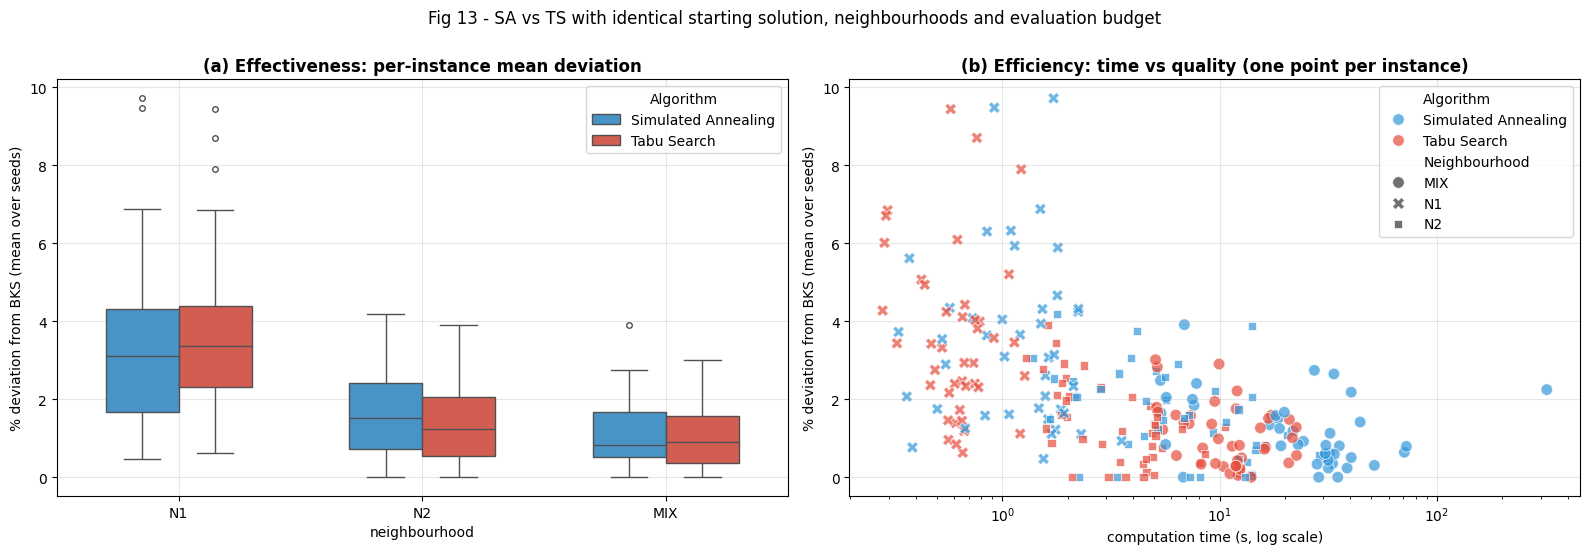

In [25]:
def plot_metaheuristic_comparability(df_combined):
    """Fig 13. SA vs TS for N1, N2 and MIX: effectiveness (box) and efficiency (time vs quality)."""
    per_inst, _ = summarize_final(df_combined)
    d = per_inst[per_inst["Method"].str.startswith(("SA", "TS"))].copy()
    d["Algorithm"] = d["Method"].str[:2].map({"SA": "Simulated Annealing", "TS": "Tabu Search"})
    d["Neighbourhood"] = d["Method"].str.split("-").str[1]
    colors = {"Simulated Annealing": "#3498db", "Tabu Search": "#e74c3c"}

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    sns.boxplot(data=d, x="Neighbourhood", y="Dev_mean", hue="Algorithm", palette=colors,
                ax=axes[0], width=0.6, fliersize=4, order=["N1", "N2", "MIX"])
    axes[0].set_title("(a) Effectiveness: per-instance mean deviation", fontweight="bold")
    axes[0].set_ylabel("% deviation from BKS (mean over seeds)"); axes[0].set_xlabel("neighbourhood")
    axes[0].grid(alpha=0.3)

    sns.scatterplot(data=d, x="Time_s", y="Dev_mean", hue="Algorithm", style="Neighbourhood",
                    s=70, alpha=0.7, palette=colors, ax=axes[1])
    axes[1].set_title("(b) Efficiency: time vs quality (one point per instance)", fontweight="bold")
    axes[1].set_ylabel("% deviation from BKS (mean over seeds)")
    axes[1].set_xlabel("computation time (s, log scale)"); axes[1].set_xscale("log"); axes[1].grid(alpha=0.3)
    fig.suptitle("Fig 13 - SA vs TS with identical starting solution, neighbourhoods and evaluation budget", y=1.0)
    _finish(fig, "fig13_sa_vs_ts")


def plot_anytime_sa_vs_ts(sa_histories, ts_histories, bks_dict, labels=None, n_grid=150):
    """Fig 14. Best-so-far % deviation against evaluated neighbours: SA (solid) vs TS (dashed), mean over seeds."""
    all_labels = sorted({k[1] for k in ts_histories}, key=sort_key)
    if labels is None:                                    # one instance per class
        first = {}
        for l in all_labels:
            first.setdefault(_cls(l), l)
        labels = list(first.values())
    nb_list = [("N1", "SA-N1", "TS-N1"), ("N2", "SA-N2", "TS-N2"), ("MIX", "SA-MIX", "TS-MIX")]
    ncol = min(4, len(labels)); nrow = int(np.ceil(len(labels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.8 * nrow), squeeze=False)
    for ax in axes.ravel()[len(labels):]:
        ax.axis("off")
    for ax, label in zip(axes.ravel(), labels):
        bks = float(bks_dict[label])
        for nb, sa_name, ts_name in nb_list:
            for name, hist, ls in ((sa_name, sa_histories, "-"), (ts_name, ts_histories, "--")):
                runs = [h for (v, l, s), h in hist.items() if v == name and l == label]
                if not runs:
                    continue
                off = SA_N_CALIB if name.startswith("SA") else 0      # SA spends 200 evaluations on calibration first
                xmax = np.mean([h[-1]["evals"] for h in runs]) + off
                grid = np.linspace(0, xmax, n_grid)
                curves = []
                for h in runs:
                    xs = np.array([lv["evals"] for lv in h]) + off; bs = np.array([lv["best"] for lv in h])
                    idx = np.clip(np.searchsorted(xs, grid, side="right") - 1, 0, None)
                    curves.append(100 * (bs[idx] - bks) / bks)
                ax.plot(grid, np.mean(curves, axis=0), ls=ls, color=PALETTE[name], lw=1.8, label=name)
        ax.set_title(label); ax.set_xlabel("evaluated neighbours"); ax.set_ylabel("best % deviation"); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=7, ncol=2)
    fig.suptitle("Fig 14 - Anytime behaviour at equal budget: SA (solid) vs TS (dashed)", y=1.0)
    _finish(fig, "fig14_anytime_sa_vs_ts")


if df_combined is not None:
    plot_metaheuristic_comparability(df_combined)
    if sa_histories and ts_histories:
        plot_anytime_sa_vs_ts(sa_histories, ts_histories, BKS)

## 13. Statistical comparison, class breakdown and export of the raw data

All tests use the **per-instance mean % deviation over the 10 seeds** (one value per instance and method), so instances, not runs, are the experimental units and the pairing is by instance.

* **Friedman test** on the held-out instances (those not used for tuning) over all 8 methods (BI-N1, BI-N2, SA-N1, SA-N2, SA-MIX, TS-N1, TS-N2, TS-MIX): do the methods differ in rank?
* **Pairwise Wilcoxon signed-rank tests** with **Holm correction** over all pairs, shown as a heat map. The focused SA-vs-TS tests (one per neighbourhood) are in section 12.2.
* **Class breakdown:** effectiveness and time by instance class (all instances).
* **Export (assignment requirement):** a spreadsheet (`scp_raw_data.xlsx`) with all raw runs, the per-instance deviation matrix, the test results, the tuning and ablation data; and text files (`scp_stat_data.txt` = matrix used in the tests on held-out instances, `scp_stat_data_all_instances.txt`, `scp_runs_raw.txt` = every run). If `openpyxl` is missing the sheets are written as CSV files.

=== 13.1 Statistical significance (held-out instances only) ===


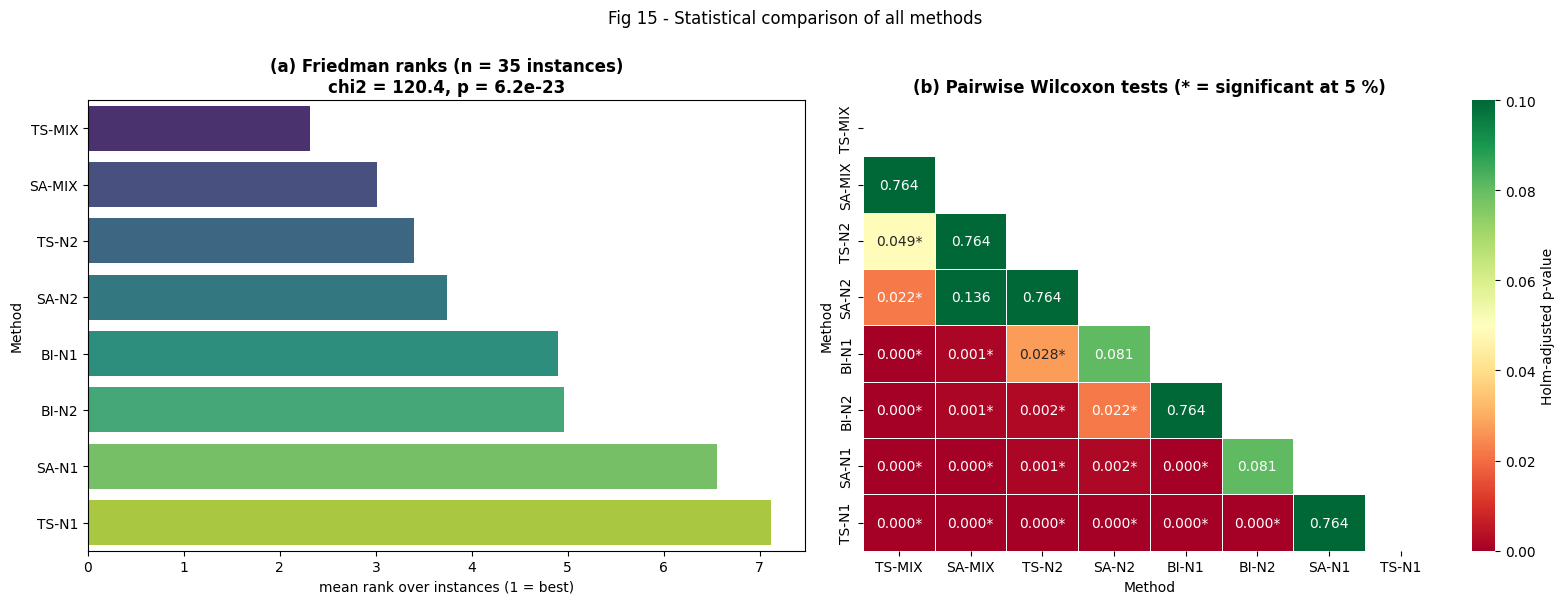

,A,B,mean_dev_A,mean_dev_B,A better on,B better on,ties,p (Wilcoxon),p (Holm)
0,BI-N1,BI-N2,2.5357,2.4220,10,15,10,0.6766,0.7643
1,BI-N1,SA-N1,2.5357,3.2965,25,1,9,0.0000,0.0002
2,BI-N1,SA-N2,2.5357,1.5477,8,22,5,0.0110,0.0807
3,BI-N1,SA-MIX,2.5357,1.1088,10,25,0,0.0001,0.0012
4,BI-N1,TS-N1,2.5357,3.6025,31,4,0,0.0000,0.0000
5,BI-N1,TS-N2,2.5357,1.4088,6,25,4,0.0028,0.0276
6,BI-N1,TS-MIX,2.5357,0.9925,4,31,0,0.0000,0.0000
7,BI-N2,SA-N1,2.4220,3.2965,25,9,1,0.0101,0.0807
8,BI-N2,SA-N2,2.4220,1.5477,7,21,7,0.0020,0.0221
9,BI-N2,SA-MIX,2.4220,1.1088,8,27,0,0.0001,0.0013



=== 13.2 Performance by instance class ===


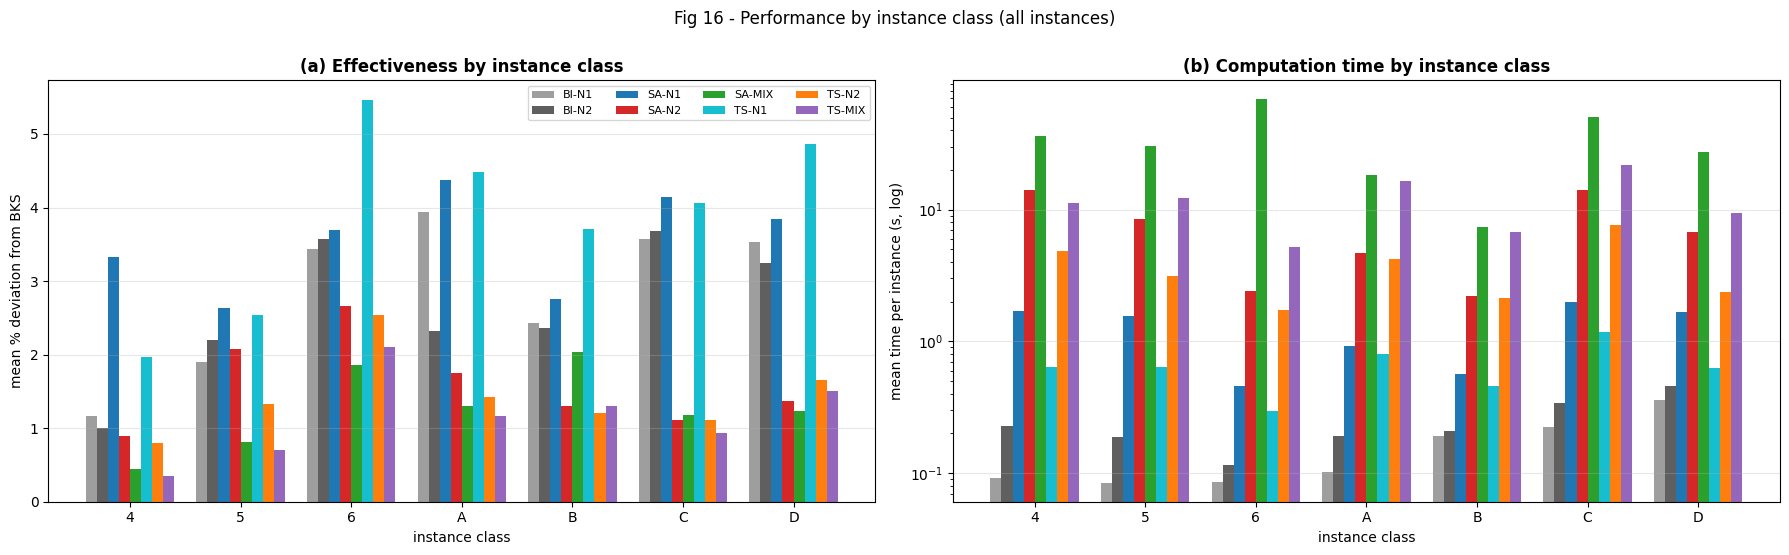


=== 13.3 Exporting raw data ===
Exported text files: scp_stat_data.txt, scp_stat_data_all_instances.txt, scp_runs_raw.txt
Exported raw data spreadsheet to: scp_raw_data.xlsx


In [26]:
# =============================================================================
# 13. Statistical comparison, class breakdown, and data export
# =============================================================================

# --- 1. Statistical helpers ---------------------------------------------------
def _dev_matrix(df_cmp, exclude=()):
    """Pivot: per-instance mean % deviation (rows = instances, columns = methods)."""
    d = df_cmp[~df_cmp["Instance"].isin(exclude)]
    piv = d.groupby(["Instance", "Method"])["Pct_Dev"].mean().unstack()
    piv = piv[[m for m in METHOD_ORDER if m in piv.columns]]
    return piv.loc[sorted(piv.index, key=sort_key)]


def statistical_tests(df_cmp, exclude=()):
    """Friedman and pairwise Wilcoxon (Holm) tests on the per-instance mean % deviation."""
    piv = _dev_matrix(df_cmp, exclude)
    ms = list(piv.columns)
    piv = piv.dropna()

    fr = friedmanchisquare(*[piv[m] for m in ms]) if len(ms) >= 3 and len(piv) >= 2 else None
    pairs = list(itertools.combinations(ms, 2))
    raw = []
    for a, b in pairs:
        try:
            raw.append(1.0 if (piv[a] == piv[b]).all() else wilcoxon(piv[a], piv[b]).pvalue)
        except ValueError:
            raw.append(1.0)
    adj = _holm(raw)
    P = pd.DataFrame(np.nan, index=ms, columns=ms)
    rows = []
    for (a, b), pr, pa in zip(pairs, raw, adj):
        P.loc[a, b] = P.loc[b, a] = pa
        d = piv[a] - piv[b]
        rows.append({"A": a, "B": b, "mean_dev_A": piv[a].mean(), "mean_dev_B": piv[b].mean(),
                     "A better on": int((d < -1e-9).sum()), "B better on": int((d > 1e-9).sum()),
                     "ties": int((d.abs() <= 1e-9).sum()), "p (Wilcoxon)": pr, "p (Holm)": pa})
    ranks = piv.rank(axis=1).mean().sort_values()
    return {"friedman": fr, "p_adj": P, "pairs": pd.DataFrame(rows), "ranks": ranks, "n_instances": len(piv)}


# --- 2. Plot: ranks and pairwise significance ----------------------------------
def plot_cmp_stats(df_cmp, exclude=()):
    st = statistical_tests(df_cmp, exclude)
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    r = st["ranks"]
    sns.barplot(x=r.values, y=r.index, hue=r.index, palette="viridis", legend=False, ax=ax[0])
    ax[0].set_xlabel("mean rank over instances (1 = best)")
    fr = st["friedman"]
    ax[0].set_title(f"(a) Friedman ranks (n = {st['n_instances']} instances)\n" +
                    (f"chi2 = {fr.statistic:.1f}, p = {fr.pvalue:.2g}" if fr else ""), fontweight="bold")
    P = st["p_adj"].loc[r.index, r.index]
    mask = np.triu(np.ones_like(P, dtype=bool))
    annot = np.array([["" if np.isnan(v) else f"{v:.3f}" + ("*" if v < 0.05 else "") for v in row] for row in P.values])
    sns.heatmap(P, mask=mask, annot=annot, fmt="", cmap="RdYlGn", vmin=0, vmax=0.1,
                cbar_kws={"label": "Holm-adjusted p-value"}, ax=ax[1], linewidths=0.5, linecolor="white")
    ax[1].set_title("(b) Pairwise Wilcoxon tests (* = significant at 5 %)", fontweight="bold")
    fig.suptitle("Fig 15 - Statistical comparison of all methods", y=1.0)
    _finish(fig, "fig15_statistics")
    return st


# --- 3. Plot: performance by instance class -------------------------------------
def plot_cmp_by_class(df_cmp, exclude=()):
    per_inst, _ = summarize_final(df_cmp, exclude_labels=exclude)
    d = per_inst.assign(Class=per_inst["Instance"].map(_cls))
    ms = _methods(d)
    fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
    t = d.groupby(["Class", "Method"])["Dev_mean"].mean().unstack()[ms]
    _grouped_bars(axes[0], t, PALETTE, "mean % deviation from BKS")
    axes[0].set_xlabel("instance class"); axes[0].legend(ncol=4, fontsize=8); axes[0].grid(axis="y", alpha=0.3)
    axes[0].set_title("(a) Effectiveness by instance class", fontweight="bold")
    t = d.groupby(["Class", "Method"])["Time_s"].mean().unstack()[ms]
    _grouped_bars(axes[1], t, PALETTE, "mean time per instance (s, log)", log=True)
    axes[1].set_xlabel("instance class"); axes[1].grid(axis="y", alpha=0.3)
    axes[1].set_title("(b) Computation time by instance class", fontweight="bold")
    fig.suptitle("Fig 16 - Performance by instance class (all instances)", y=1.0)
    _finish(fig, "fig16_by_class")


# --- 4. Export of the raw data (assignment requirement) -------------------------
def export_raw_data(df_cmp, exclude=(), extra=None, xlsx_path="scp_raw_data.xlsx",
                    txt_path="scp_stat_data.txt", txt_all_path="scp_stat_data_all_instances.txt",
                    runs_txt_path="scp_runs_raw.txt"):
    """Spreadsheet + text files with the raw data used for the statistical tests.
    `exclude` = tuning instances: the tests are run on the remaining (held-out) instances."""
    piv_all, piv_held = _dev_matrix(df_cmp), _dev_matrix(df_cmp, exclude)
    st_held, st_all = statistical_tests(df_cmp, exclude), statistical_tests(df_cmp)

    with open(txt_path, "w") as f:
        f.write("# Per-instance mean % deviation from the best known solution (mean over seeds)\n")
        f.write(f"# HELD-OUT instances only (tuning instances excluded: {', '.join(exclude) or 'none'})\n")
        f.write("# Rows: instances; columns: methods. Input of the Friedman and Wilcoxon tests (tab separated).\n")
        piv_held.round(6).to_csv(f, sep="\t")
    with open(txt_all_path, "w") as f:
        f.write("# Per-instance mean % deviation from the best known solution (mean over seeds), ALL instances\n")
        piv_all.round(6).to_csv(f, sep="\t")
    cols = [c for c in ["Instance", "Method", "Seed", "BKS", "Init_Cost", "Final_Cost", "Pct_Dev",
                        "Pct_Dev_noPolish", "Evaluations", "Time_s"] if c in df_cmp.columns]
    df_cmp[cols].to_csv(runs_txt_path, sep="\t", index=False)
    print(f"Exported text files: {txt_path}, {txt_all_path}, {runs_txt_path}")

    dev_sheet = piv_all.copy()
    dev_sheet.insert(0, "Held_out", ~dev_sheet.index.isin(exclude))
    sheets = {
        "README": pd.DataFrame({
            "Sheet": ["Runs", "Dev_per_instance", "Tests_heldout", "Tests_all", "SA_vs_TS_heldout",
                      "SA_vs_TS_all", "SA_tuning", "TS_tuning", "TS_ablation", "SA_mix_probability", "SA_start_ablation"],
            "Content": ["every run of BI, SA and TS (one row per run)",
                        "per-instance mean % deviation over seeds, all instances (Held_out = not used for tuning)",
                        "pairwise Wilcoxon + Holm over all methods, held-out instances",
                        "same, all instances",
                        "matched SA-X vs TS-X tests (same neighbourhood, seed and evaluation budget), held-out",
                        "same, all instances",
                        "SA tuning runs (factorial design)", "TS tuning runs (factorial design)",
                        "TS building-block ablation runs", "SA-MIX probability sensitivity runs",
                        "SA starting-solution ablation runs"]}),
        "Runs": df_cmp,
        "Dev_per_instance": dev_sheet.reset_index(),
        "Tests_heldout": st_held["pairs"], "Tests_all": st_all["pairs"],
        "SA_vs_TS_heldout": sa_vs_ts_table(df_cmp, exclude), "SA_vs_TS_all": sa_vs_ts_table(df_cmp),
    }
    for name, d in (extra or {}).items():
        if d is not None and len(d):
            sheets[name] = d
    try:
        with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
            for name, d in sheets.items():
                d.to_excel(xw, sheet_name=name[:31], index=False)
        print(f"Exported raw data spreadsheet to: {xlsx_path}")
    except ImportError:
        for name, d in sheets.items():
            d.to_csv(f"scp_raw_{name}.csv", index=False)
        print("openpyxl not installed. Saved the sheets as CSV files instead.")


# =============================================================================
# EXECUTE SECTION 13
# =============================================================================
if df_combined is not None:
    print("=== 13.1 Statistical significance (held-out instances only) ===")
    st_held = plot_cmp_stats(df_combined, exclude=tune_labels)
    display(st_held["pairs"].round(4))

    print("\n=== 13.2 Performance by instance class ===")
    plot_cmp_by_class(df_combined)

    print("\n=== 13.3 Exporting raw data ===")
    export_raw_data(df_combined, exclude=tune_labels,
                    extra={"SA_tuning": df_tune, "TS_tuning": df_ts_tune, "TS_ablation": df_ts_abl,
                           "SA_mix_probability": df_mix, "SA_start_ablation": df_start})

## 14. Data persistence

The raw result tables are written by the experiment cells themselves (`scp_sa_tuning.csv`, `scp_sa_results.csv`, `scp_sa_mix_sensitivity.csv`, `scp_sa_start_ablation.csv`, `scp_ts_tuning.csv`, `scp_ts_ablation.csv`, `scp_ts_results.csv`, and the pickled histories `scp_sa_histories.pkl`, `scp_ts_histories.pkl`), so a crashed or restarted kernel only needs the setup cells (sections 1-8) to be re-run: with `RECOMPUTE` left at `False` every experiment cell reloads its file. This cell stores the merged SA + TS data set (`scp_combined_results.csv`) that the statistics and the export were computed from.

In [27]:
COMBINED_CSV = "scp_combined_results.csv"

if df_combined is not None:
    df_combined.to_csv(COMBINED_CSV, index=False)
    print(f"Saved merged results ({len(df_combined)} runs, methods: {df_combined['Method'].unique().tolist()}) to {COMBINED_CSV}")
elif Path(COMBINED_CSV).exists():
    df_combined = pd.read_csv(COMBINED_CSV)
    print(f"Loaded previously saved results from {COMBINED_CSV}: {len(df_combined)} runs.")
else:
    print("No results available yet: run the SA and TS experiment cells first.")

Saved merged results (2604 runs, methods: ['BI-N1', 'BI-N2', 'SA-N1', 'SA-N2', 'SA-MIX', 'TS-N1', 'TS-N2', 'TS-MIX']) to scp_combined_results.csv
